In [1]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))


In [2]:
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

In [3]:
#gbif_try_glonaf2 <- fread("/net/scratch/swolf/GBIF/gbif_try6_s1_5000_glonaf_status.csv")
#gbif_try_glonaf <- fread("/net/scratch/swolf/GBIF/gbif_try6_CS_glonaf_status.csv")
#gbif_try_glonaf <- fread("/net/scratch/swolf/GBIF/GBIF_s1_5000_try6_GloNAF_WCVP_status_woody.csv")
gbif_try_glonaf <- fread("/net/scratch/swolf/GBIF/GBIF_try6_GloNAF_WCVP_status_woodiness_CS.csv")


head(gbif_try_glonaf)

gbifID,speciesKey,decimalLatitude,decimalLongitude,h3_res3,h3_res4,X.X3117.,X.X14.,X.X50.,X.X146.,⋯,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.,most_common_pft,majority_status,woodiness
<int64>,<int>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
891018389,2986175,37.81738,-122.0341,832830fffffffff,842830dffffffff,14.198018,22.394893,1.8711526,19.09068,⋯,2.054130,0.4096437,90.06101,139.73576,1774.1975,-3.088086,0.7170612,Shrub,native,woody
891018395,2878586,37.93479,-122.1528,832830fffffffff,8428309ffffffff,9.527582,18.021850,1.8542082,25.20681,⋯,2.204626,2.7929593,75.85665,86.86699,235.6233,-2.107607,0.5244097,Tree,native,woody
891018399,2928026,37.16354,-121.4834,832834fffffffff,8428345ffffffff,12.834863,9.708971,0.8664297,NA,⋯,1.147330,NA,97.96611,NA,6980.9510,NA,0.5196287,Grass,native,non-woody
891018400,3039404,37.89495,-121.9295,832830fffffffff,842830dffffffff,4.307864,14.872387,3.4717732,30.36493,⋯,1.588747,3.6377510,79.49740,104.98971,265.6407,-2.293326,0.6810611,Shrub,native,woody
891018401,2878384,37.88037,-121.9101,832830fffffffff,842830dffffffff,7.470983,14.708481,1.9751395,30.55207,⋯,1.711807,4.1715545,87.50078,36.89623,513.2988,-2.704216,0.7399179,Tree,native,woody
891018402,5298502,38.58038,-123.3133,832831fffffffff,8428311ffffffff,12.687887,17.383079,1.5956363,32.10343,⋯,1.025867,0.3838454,81.96427,190.18055,3880.6637,1.950235,0.3792678,Grass,native,non-woody


## Some stats on the data

In [4]:
# remane "majority_status" to "status"
setnames(gbif_try_glonaf, old = "majority_status", new = "status")

In [5]:
dim(gbif_try_glonaf)

[1] 64141358       46

In [6]:
# number of NA in status
sum(is.na(gbif_try_glonaf$X.X3117.))

[1] 4311718

In [7]:
# if status is "" replace with NA
gbif_try_glonaf[status == "", status := NA]

In [8]:
# summary of status
table(gbif_try_glonaf$status, useNA = "ifany")


    native non-native       <NA> 
  51783950   11419062     938346 

In [9]:
# percentage of each status
prop.table(table(gbif_try_glonaf$status, useNA = "ifany"))


    native non-native       <NA> 
0.80734103 0.17802963 0.01462934 

In [10]:
# number of species in dataset
length(unique(gbif_try_glonaf$speciesKey)) 

length(unique(gbif_try_glonaf[status == "native"]$speciesKey)) 

# number of naturalized species in dataset
length(unique(gbif_try_glonaf[status == "non-native"]$speciesKey)) 


[1] 42520

[1] 41814

[1] 5521

## Distrubutions of traits

In [11]:
glonaf_cols <- grep("^X\\.", names(gbif_try_glonaf), value = TRUE)


# log10 transform all glonaf columns, except for columns X.X4., 13, 14, 15, 47, 50, 78, 95, 146, 223, 3117, 3120
glonaf_cols_to_transform <- setdiff(glonaf_cols, c("X.X4.", "X.X13.", "X.X14.", "X.X15.", "X.X47.", "X.X50.", "X.X78.", "X.X95.", "X.X146.", "X.X223.", "X.X3117.", "X.X3120."))    
for (col in glonaf_cols_to_transform) {
  gbif_try_glonaf[[col]] <- log10(gbif_try_glonaf[[col]]) 
}

## Remove conifers

In [12]:
# read "/net/scratch/swolf/GBIF/gbif_h3/res3_res4_cs_conifers.csv"
gbif_conifers <- fread("/net/scratch/swolf/GBIF/gbif_h3/res3_res4_cs_conifers.csv")


In [13]:
# remove rows from gbif_try_glonaf that appear in  gbif_conifers (based on "gbifID")
gbif_try_glonaf <- gbif_try_glonaf[!gbifID %in% gbif_conifers$gbifID]



In [14]:
dim(gbif_try_glonaf)

[1] 63075137       46

# Aggregate observations to grid-cell averages

In [15]:
library(data.table)

calc_stats <- function(dt, trait_cols, h3_cols = c("h3_res3", "h3_res4")) {
  
  dt <- as.data.table(dt)
  
  all_results <- rbindlist(lapply(h3_cols, function(h3_col) {
  cat("Processing by:", h3_col, "\n")
  
  results <- dt[, {
    
    # Basic counts
    count_all <- sum(status %in% c("native", "non-native"), na.rm = TRUE)
    count_native <- sum(status == "native", na.rm = TRUE)
    count_sp_all <- uniqueN(speciesKey[status %in% c("native", "non-native")], na.rm = TRUE)
    count_sp_native <- uniqueN(speciesKey[status == "native"], na.rm = TRUE)
    
    rec_woody <- sum(woodiness == "woody", na.rm = TRUE)
    rec_nonwoody <- sum(woodiness == "non-woody", na.rm = TRUE)

    perc_woody <- if (.N > 0) round(rec_woody / .N * 100, 2) else NA_real_
    perc_nonwoody <- if (.N > 0) round(rec_nonwoody / .N * 100, 2) else NA_real_
    
    # Trait-wise stats
    trait_stats <- lapply(.SD, function(x) {
    x <- as.numeric(x)
    
    #all_x <- x[!is.na(x)]
    all_x <- x[status %in% c("native", "non-native") & !is.na(x)]
    native_x <- x[status == "native" & !is.na(x)]
    
    # Trimmed means
    if (length(all_x) > 1) {
      all_trim <- all_x[all_x > quantile(all_x, 0.01, na.rm = TRUE) &
              all_x < quantile(all_x, 0.99, na.rm = TRUE)]
    } else all_trim <- all_x
    
    if (length(native_x) > 1) {
      native_trim <- native_x[native_x > quantile(native_x, 0.01, na.rm = TRUE) &
                  native_x < quantile(native_x, 0.99, na.rm = TRUE)]
    } else native_trim <- native_x
    
    mean_all <- round(mean(all_trim, na.rm = TRUE), 3)
    mean_native <- round(mean(native_trim, na.rm = TRUE), 3)
    median_all <- round(median(all_x, na.rm = TRUE), 3)
    median_native <- round(median(native_x, na.rm = TRUE), 3)
    
    percent_change_mean <- if (!is.na(mean_native) && mean_native != 0) {
      round((mean_all - mean_native) / abs(mean_native) * 100, 2)
    } else NA_real_
    
    percent_change_median <- if (!is.na(median_native) && median_native != 0) {
      round((median_all - median_native) / abs(median_native) * 100, 2)
    } else NA_real_
    
    c(
      mean_all = mean_all,
      mean_native = mean_native,
      median_all = median_all,
      median_native = median_native,
      percent_change_mean = percent_change_mean,
      percent_change_median = percent_change_median
    )
    })
    
    c(
    .(count_all, count_native, count_sp_all, count_sp_native, rec_woody, rec_nonwoody,
    perc_woody, perc_nonwoody),
    unlist(trait_stats, recursive = FALSE)
    )
  }, by = h3_col, .SDcols = trait_cols]
  
  # Rename grouping column to a consistent name
  setnames(results, old = h3_col, new = "h3_cell")
  results[, resolution := h3_col]
  
  return(results)
  }), use.names = TRUE, fill = TRUE, idcol = NULL)
  
  return(all_results)
}

# Test loop for res_3 and all dataset
trait_columns <- grep("^X\\.X\\d+\\.", names(gbif_try_glonaf), value = TRUE)

# Define the dataset
dt <- gbif_try_glonaf

# Define the resolution to process
h3_col <- "h3_res3"

cat("\n--- Testing dataset: all ---\n")
cat("   -> Resolution:", h3_col, "\n")

# Run the calculation
result <- calc_stats(dt, trait_columns, h3_cols = h3_col)

# Build the output path
output_file <- paste0(
    "/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_",
    h3_col, "_try6_summary_stats_all_CS_log10_woody_angio.csv"
)

# Save to CSV
fwrite(result, output_file, row.names = FALSE, quote = TRUE)
cat("      Saved:", output_file, "\n")



--- Testing dataset: all ---
   -> Resolution: h3_res3 


Processing by: h3_res3 
      Saved: /net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res3_try6_summary_stats_all_CS_log10_woody_angio.csv 


In [16]:
## Add PC1 and PC2
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

#gbif_summary <- fread("/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_summary_stats.csv")
#gbif_summary <- fread("/net/scratch/swolf/GBIF/gbif_res3_try6_sc_stats.csv")
#gbif_summary <- fread("/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_res3_try6_s1_5000_summary_stats_all.csv")
#gbif_summary <- fread("/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_res3_try6_s1_5000_summary_stats_woody.csv")
#gbif_summary <- fread("/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_res3_try6_s1_5000_summary_stats_nonwoody.csv")

#gbif_summary <- fread("/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res3_try6_summary_stats_all_CS.csv")

gbif_summary <- fread("/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res3_try6_summary_stats_all_CS_log10_woody_angio.csv")


head(gbif_summary)

h3_cell,V1,V2,V3,V4,V5,V6,V7,V8,X.X3117..mean_all,⋯,X.X78..median_native,X.X78..percent_change_mean,X.X78..percent_change_median,X.X4..mean_all,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,resolution
<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
832830fffffffff,525930,370050,2035,1213,165230,343606,31.34,65.18,18.415,⋯,-0.862,56.31,45.59,0.441,0.471,0.430,0.459,-6.37,-6.32,h3_res3
832834fffffffff,439943,325248,1766,1032,153694,274171,34.79,62.07,18.223,⋯,-0.969,48.02,25.80,0.452,0.479,0.445,0.470,-5.64,-5.32,h3_res3
832831fffffffff,62389,49599,1244,753,18498,41557,29.61,66.53,18.910,⋯,-1.141,41.04,26.29,0.441,0.461,0.430,0.458,-4.34,-6.11,h3_res3
832655fffffffff,18412,14430,964,729,5741,12240,30.99,66.07,22.962,⋯,-0.269,95.39,7.06,0.438,0.448,0.435,0.438,-2.23,-0.68,h3_res3
832a16fffffffff,60230,36855,1386,835,23115,34918,38.19,57.69,25.569,⋯,-0.869,61.53,62.83,0.424,0.444,0.411,0.437,-4.50,-5.95,h3_res3
8329a5fffffffff,75342,48826,1158,595,37174,36368,49.13,48.06,15.846,⋯,-0.039,73.78,1010.26,0.460,0.485,0.465,0.478,-5.15,-2.72,h3_res3


In [17]:
# rename V1, V2, V3 , V4 to count_all, count_native, count_sp_all, count_sp_native
setnames(gbif_summary, old = c("h3_cell", "V1", "V2", "V3", "V4"), 
    new = c("h3_res3", "count_all", "count_native", "count_sp_all", "count_sp_native"))

In [18]:
dim(gbif_summary)

[1] 10181   232

In [19]:
# are there rows where gbif_summary$count_native == 0
nrow(gbif_summary[gbif_summary$count_native == 0, ])

[1] 444

In [20]:
nrow(gbif_summary[gbif_summary$count_native < 100, ])

[1] 5626

In [21]:
# filter out rows where count_native is less than 100
#gbif_summary <- gbif_summary[count_native >= 100]


# filter out rows where count_native is 0
gbif_summary <- gbif_summary[count_native > 0]
dim(gbif_summary)
dim(gbif_summary)

[1] 9737  232

[1] 9737  232

In [22]:
head(gbif_summary)

h3_res3,count_all,count_native,count_sp_all,count_sp_native,V5,V6,V7,V8,X.X3117..mean_all,⋯,X.X78..median_native,X.X78..percent_change_mean,X.X78..percent_change_median,X.X4..mean_all,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,resolution
<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
832830fffffffff,525930,370050,2035,1213,165230,343606,31.34,65.18,18.415,⋯,-0.862,56.31,45.59,0.441,0.471,0.430,0.459,-6.37,-6.32,h3_res3
832834fffffffff,439943,325248,1766,1032,153694,274171,34.79,62.07,18.223,⋯,-0.969,48.02,25.80,0.452,0.479,0.445,0.470,-5.64,-5.32,h3_res3
832831fffffffff,62389,49599,1244,753,18498,41557,29.61,66.53,18.910,⋯,-1.141,41.04,26.29,0.441,0.461,0.430,0.458,-4.34,-6.11,h3_res3
832655fffffffff,18412,14430,964,729,5741,12240,30.99,66.07,22.962,⋯,-0.269,95.39,7.06,0.438,0.448,0.435,0.438,-2.23,-0.68,h3_res3
832a16fffffffff,60230,36855,1386,835,23115,34918,38.19,57.69,25.569,⋯,-0.869,61.53,62.83,0.424,0.444,0.411,0.437,-4.50,-5.95,h3_res3
8329a5fffffffff,75342,48826,1158,595,37174,36368,49.13,48.06,15.846,⋯,-0.039,73.78,1010.26,0.460,0.485,0.465,0.478,-5.15,-2.72,h3_res3


Sum of counts matches the number of obs. labelled native or non-native:

In [23]:
dim(gbif_summary)

[1] 9737  232

In [24]:
# Sum of count_all
64141358 - sum(gbif_summary$count_all, na.rm = TRUE)

[1] 1990733

In [25]:
# Select columns whose names end with "_median_all" or "_median_native"
#trait_matrix <- gbif_summary[, grep("median_(all|native)$", names(gbif_summary)), with = FALSE]

# Select columns whose names end with "_mean_all" or "_mean_native"
trait_matrix <- gbif_summary[, grep("mean_(all|native)$", names(gbif_summary)), with = FALSE]

head(trait_matrix)


X.X3117..mean_all,X.X3117..mean_native,X.X14..mean_all,X.X14..mean_native,X.X50..mean_all,X.X50..mean_native,X.X146..mean_all,X.X146..mean_native,X.X3120..mean_all,X.X3120..mean_native,⋯,X.X95..mean_all,X.X95..mean_native,X.X138..mean_all,X.X138..mean_native,X.X1080..mean_all,X.X1080..mean_native,X.X78..mean_all,X.X78..mean_native,X.X4..mean_all,X.X4..mean_native
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
18.415,16.593,23.107,21.804,1.510,1.542,23.548,24.913,4.836,4.422,⋯,89.797,88.692,2.432,2.370,3.431,3.375,-0.374,-0.856,0.441,0.471
18.223,16.205,22.759,21.529,1.536,1.562,23.790,25.006,4.682,4.302,⋯,89.831,88.816,2.450,2.376,3.418,3.346,-0.459,-0.883,0.452,0.479
18.910,17.914,22.240,21.274,1.410,1.417,24.216,25.397,4.902,4.705,⋯,89.465,88.967,2.451,2.384,3.415,3.366,-0.615,-1.043,0.441,0.461
22.962,22.623,23.668,22.728,1.177,1.157,23.782,25.091,5.163,5.085,⋯,86.548,85.651,2.467,2.431,3.407,3.399,-0.007,-0.152,0.438,0.448
25.569,26.225,24.333,22.736,1.112,1.044,21.743,23.582,5.293,5.146,⋯,87.573,85.365,2.559,2.399,3.419,3.398,-0.252,-0.655,0.424,0.444
15.846,13.327,23.896,22.623,1.784,1.805,22.715,23.931,4.401,3.893,⋯,90.365,89.965,2.612,2.476,3.361,3.270,0.391,0.225,0.460,0.485


In [26]:
dim(trait_matrix)

[1] 9737   74

In [27]:
# colbind h3_res3	count_all	count_native	count_sp_all	count_sp_native from gbif_summary to trait_matrix
mean_data <- cbind(gbif_summary[, .(h3_res3, count_all, count_native, count_sp_all, count_sp_native)], trait_matrix)

head(mean_data)

h3_res3,count_all,count_native,count_sp_all,count_sp_native,X.X3117..mean_all,X.X3117..mean_native,X.X14..mean_all,X.X14..mean_native,X.X50..mean_all,⋯,X.X95..mean_all,X.X95..mean_native,X.X138..mean_all,X.X138..mean_native,X.X1080..mean_all,X.X1080..mean_native,X.X78..mean_all,X.X78..mean_native,X.X4..mean_all,X.X4..mean_native
<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
832830fffffffff,525930,370050,2035,1213,18.415,16.593,23.107,21.804,1.510,⋯,89.797,88.692,2.432,2.370,3.431,3.375,-0.374,-0.856,0.441,0.471
832834fffffffff,439943,325248,1766,1032,18.223,16.205,22.759,21.529,1.536,⋯,89.831,88.816,2.450,2.376,3.418,3.346,-0.459,-0.883,0.452,0.479
832831fffffffff,62389,49599,1244,753,18.910,17.914,22.240,21.274,1.410,⋯,89.465,88.967,2.451,2.384,3.415,3.366,-0.615,-1.043,0.441,0.461
832655fffffffff,18412,14430,964,729,22.962,22.623,23.668,22.728,1.177,⋯,86.548,85.651,2.467,2.431,3.407,3.399,-0.007,-0.152,0.438,0.448
832a16fffffffff,60230,36855,1386,835,25.569,26.225,24.333,22.736,1.112,⋯,87.573,85.365,2.559,2.399,3.419,3.398,-0.252,-0.655,0.424,0.444
8329a5fffffffff,75342,48826,1158,595,15.846,13.327,23.896,22.623,1.784,⋯,90.365,89.965,2.612,2.476,3.361,3.270,0.391,0.225,0.460,0.485



### Imputation of missing data

Get info on degreee of missingness: Missingness is quite low. So I will use a simple Mean or Median Imputation, i.e. Replace missing values with the column mean/median


In [28]:

# Calculate total missingness
total_missingness <- sum(is.na(trait_matrix)) / prod(dim(trait_matrix))
print(total_missingness)



[1] 0.06451013


In [29]:
# Get the column names of trait_matrix and add "h3_res3"
trait_columns <- c(colnames(trait_matrix), "h3_res3", "count_native", "count_all")

In [30]:
library(dplyr)
library(tidyr)

# Subset df2 based on the column names of df
gbif_average <- gbif_summary[, trait_columns, with = FALSE]
head(gbif_average)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




X.X3117..mean_all,X.X3117..mean_native,X.X14..mean_all,X.X14..mean_native,X.X50..mean_all,X.X50..mean_native,X.X146..mean_all,X.X146..mean_native,X.X3120..mean_all,X.X3120..mean_native,⋯,X.X138..mean_native,X.X1080..mean_all,X.X1080..mean_native,X.X78..mean_all,X.X78..mean_native,X.X4..mean_all,X.X4..mean_native,h3_res3,count_native,count_all
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<int>
18.415,16.593,23.107,21.804,1.510,1.542,23.548,24.913,4.836,4.422,⋯,2.370,3.431,3.375,-0.374,-0.856,0.441,0.471,832830fffffffff,370050,525930
18.223,16.205,22.759,21.529,1.536,1.562,23.790,25.006,4.682,4.302,⋯,2.376,3.418,3.346,-0.459,-0.883,0.452,0.479,832834fffffffff,325248,439943
18.910,17.914,22.240,21.274,1.410,1.417,24.216,25.397,4.902,4.705,⋯,2.384,3.415,3.366,-0.615,-1.043,0.441,0.461,832831fffffffff,49599,62389
22.962,22.623,23.668,22.728,1.177,1.157,23.782,25.091,5.163,5.085,⋯,2.431,3.407,3.399,-0.007,-0.152,0.438,0.448,832655fffffffff,14430,18412
25.569,26.225,24.333,22.736,1.112,1.044,21.743,23.582,5.293,5.146,⋯,2.399,3.419,3.398,-0.252,-0.655,0.424,0.444,832a16fffffffff,36855,60230
15.846,13.327,23.896,22.623,1.784,1.805,22.715,23.931,4.401,3.893,⋯,2.476,3.361,3.270,0.391,0.225,0.460,0.485,8329a5fffffffff,48826,75342


In [31]:
# Reshape to long format
gbif_average_long <- gbif_average %>%
  pivot_longer(
    cols = starts_with("X."),  
    names_to = c("trait", "group"),  
    names_pattern = "(.+?)\\.(mean_all|mean_native)"
  ) %>%
  mutate(group = ifelse(group == "mean_all", "all", "native"))  # Rename values for clarity
# merge count_native and count_all into one column "count" based on group
gbif_average_long <- gbif_average_long %>%
  mutate(count = ifelse(group == "all", count_all, count_native)) %>%
  select(-count_all, -count_native)  # Remove the original count columns
head(gbif_average_long)

h3_res3,trait,group,value,count
<chr>,<chr>,<chr>,<dbl>,<int>
832830fffffffff,X.X3117.,all,18.415,525930
832830fffffffff,X.X3117.,native,16.593,370050
832830fffffffff,X.X14.,all,23.107,525930
832830fffffffff,X.X14.,native,21.804,370050
832830fffffffff,X.X50.,all,1.510,525930
832830fffffffff,X.X50.,native,1.542,370050


In [32]:

# Pivot back to wide format
gbif_average_wide <- gbif_average_long %>%
  pivot_wider(
    names_from = trait,  
    values_from = value
  )

head(gbif_average_wide)

h3_res3,group,count,X.X3117.,X.X14.,X.X50.,X.X146.,X.X3120.,X.X224.,X.X297.,⋯,X.X223.,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
832830fffffffff,all,525930,18.415,23.107,1.510,23.548,4.836,0.512,0.990,⋯,27.297,0.516,3.568,0.076,-0.434,89.797,2.432,3.431,-0.374,0.441
832830fffffffff,native,370050,16.593,21.804,1.542,24.913,4.422,0.496,0.987,⋯,27.223,0.532,3.536,0.097,-0.397,88.692,2.370,3.375,-0.856,0.471
832834fffffffff,all,439943,18.223,22.759,1.536,23.790,4.682,0.496,1.001,⋯,27.278,0.523,3.561,0.076,-0.417,89.831,2.450,3.418,-0.459,0.452
832834fffffffff,native,325248,16.205,21.529,1.562,25.006,4.302,0.478,1.003,⋯,27.321,0.545,3.534,0.093,-0.364,88.816,2.376,3.346,-0.883,0.479
832831fffffffff,all,62389,18.910,22.240,1.410,24.216,4.902,0.507,0.995,⋯,27.538,0.512,3.577,0.075,-0.439,89.465,2.451,3.415,-0.615,0.441
832831fffffffff,native,49599,17.914,21.274,1.417,25.397,4.705,0.503,0.999,⋯,27.596,0.534,3.547,0.089,-0.421,88.967,2.384,3.366,-1.043,0.461


In [33]:
# filter gbif_average_wide for group == "native"
gbif_average_wide_native <- gbif_average_wide %>%   
    filter(group == "native")

gbif_average_wide_all <- gbif_average_wide %>%   
    filter(group == "all")

head(gbif_average_wide_native)
head(gbif_average_wide_all)

h3_res3,group,count,X.X3117.,X.X14.,X.X50.,X.X146.,X.X3120.,X.X224.,X.X297.,⋯,X.X223.,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
832830fffffffff,native,370050,16.593,21.804,1.542,24.913,4.422,0.496,0.987,⋯,27.223,0.532,3.536,0.097,-0.397,88.692,2.370,3.375,-0.856,0.471
832834fffffffff,native,325248,16.205,21.529,1.562,25.006,4.302,0.478,1.003,⋯,27.321,0.545,3.534,0.093,-0.364,88.816,2.376,3.346,-0.883,0.479
832831fffffffff,native,49599,17.914,21.274,1.417,25.397,4.705,0.503,0.999,⋯,27.596,0.534,3.547,0.089,-0.421,88.967,2.384,3.366,-1.043,0.461
832655fffffffff,native,14430,22.623,22.728,1.157,25.091,5.085,0.487,0.973,⋯,28.738,0.620,3.591,0.054,-0.393,85.651,2.431,3.399,-0.152,0.448
832a16fffffffff,native,36855,26.225,22.736,1.044,23.582,5.146,0.419,1.020,⋯,29.630,0.544,3.627,0.071,-0.495,85.365,2.399,3.398,-0.655,0.444
8329a5fffffffff,native,48826,13.327,22.623,1.805,23.931,3.893,0.420,0.987,⋯,29.381,0.505,3.521,0.045,-0.262,89.965,2.476,3.270,0.225,0.485


h3_res3,group,count,X.X3117.,X.X14.,X.X50.,X.X146.,X.X3120.,X.X224.,X.X297.,⋯,X.X223.,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
832830fffffffff,all,525930,18.415,23.107,1.510,23.548,4.836,0.512,0.990,⋯,27.297,0.516,3.568,0.076,-0.434,89.797,2.432,3.431,-0.374,0.441
832834fffffffff,all,439943,18.223,22.759,1.536,23.790,4.682,0.496,1.001,⋯,27.278,0.523,3.561,0.076,-0.417,89.831,2.450,3.418,-0.459,0.452
832831fffffffff,all,62389,18.910,22.240,1.410,24.216,4.902,0.507,0.995,⋯,27.538,0.512,3.577,0.075,-0.439,89.465,2.451,3.415,-0.615,0.441
832655fffffffff,all,18412,22.962,23.668,1.177,23.782,5.163,0.480,0.972,⋯,28.499,0.589,3.587,0.055,-0.398,86.548,2.467,3.407,-0.007,0.438
832a16fffffffff,all,60230,25.569,24.333,1.112,21.743,5.293,0.426,0.976,⋯,29.040,0.501,3.606,0.067,-0.474,87.573,2.559,3.419,-0.252,0.424
8329a5fffffffff,all,75342,15.846,23.896,1.784,22.715,4.401,0.480,0.973,⋯,28.791,0.500,3.545,0.043,-0.322,90.365,2.612,3.361,0.391,0.460


In [34]:

# Impute missing values in the trait matrix (combined_data)
gbif_imputed_native <- gbif_average_wide_native %>%
  #mutate(across(starts_with("X."), ~ifelse(is.na(.), median(., na.rm = TRUE), .)))
  mutate(across(starts_with("X."), ~ifelse(is.na(.), mean(., na.rm = TRUE), .)))

gbif_imputed_all <- gbif_average_wide_all %>%
  #mutate(across(starts_with("X."), ~ifelse(is.na(.), median(., na.rm = TRUE), .)))
  mutate(across(starts_with("X."), ~ifelse(is.na(.), mean(., na.rm = TRUE), .)))

# Check the modified dataframe
head(gbif_imputed_native)

h3_res3,group,count,X.X3117.,X.X14.,X.X50.,X.X146.,X.X3120.,X.X224.,X.X297.,⋯,X.X223.,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
832830fffffffff,native,370050,16.593,21.804,1.542,24.913,4.422,0.496,0.987,⋯,27.223,0.532,3.536,0.097,-0.397,88.692,2.370,3.375,-0.856,0.471
832834fffffffff,native,325248,16.205,21.529,1.562,25.006,4.302,0.478,1.003,⋯,27.321,0.545,3.534,0.093,-0.364,88.816,2.376,3.346,-0.883,0.479
832831fffffffff,native,49599,17.914,21.274,1.417,25.397,4.705,0.503,0.999,⋯,27.596,0.534,3.547,0.089,-0.421,88.967,2.384,3.366,-1.043,0.461
832655fffffffff,native,14430,22.623,22.728,1.157,25.091,5.085,0.487,0.973,⋯,28.738,0.620,3.591,0.054,-0.393,85.651,2.431,3.399,-0.152,0.448
832a16fffffffff,native,36855,26.225,22.736,1.044,23.582,5.146,0.419,1.020,⋯,29.630,0.544,3.627,0.071,-0.495,85.365,2.399,3.398,-0.655,0.444
8329a5fffffffff,native,48826,13.327,22.623,1.805,23.931,3.893,0.420,0.987,⋯,29.381,0.505,3.521,0.045,-0.262,89.965,2.476,3.270,0.225,0.485


In [35]:
# bind gbif_imputed_native and gbif_imputed_all together
gbif_imputed <- bind_rows(gbif_imputed_native, gbif_imputed_all)

#sort by h3_res3
gbif_imputed <- gbif_imputed %>% arrange(h3_res3)
head(gbif_imputed)
#

h3_res3,group,count,X.X3117.,X.X14.,X.X50.,X.X146.,X.X3120.,X.X224.,X.X297.,⋯,X.X223.,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
83001afffffffff,native,10,20.22700,18.07100,1.302000,24.00000,9.098000,0.4530000,0.9905013,⋯,31.77300,-0.0020000,3.926000,0.00000000,-0.8410000,88.58300,2.195000,3.087000,-0.6660000,0.3390000
83001afffffffff,all,10,20.22700,18.07100,1.302000,24.00000,9.098000,0.4530000,0.9889911,⋯,31.77300,-0.0020000,3.926000,0.00000000,-0.8410000,88.58300,2.195000,3.087000,-0.6660000,0.3390000
83001cfffffffff,native,1,17.09058,22.53509,1.620418,24.02538,4.216905,0.4419801,0.9905013,⋯,29.02357,0.5438886,3.486748,0.04050394,-0.2806727,88.40506,2.396332,3.353484,0.4164583,0.4752718
83001cfffffffff,all,1,15.25900,23.15237,1.235000,23.40475,8.495000,0.4470000,0.9260000,⋯,32.15500,-0.1190000,3.810000,0.00100000,-0.7440000,92.09900,2.545000,3.121000,-0.5630000,0.4689424
83001efffffffff,native,4,18.86200,18.34200,1.395000,22.47800,5.820000,0.5200000,0.9905013,⋯,30.30900,0.0410000,3.985000,0.01900000,-0.6780000,88.40506,2.142000,3.848000,-0.8270000,0.2670000
83001efffffffff,all,4,18.86200,18.34200,1.395000,22.47800,5.820000,0.5200000,0.9889911,⋯,30.30900,0.0410000,3.985000,0.01900000,-0.6780000,88.70883,2.142000,3.848000,-0.8270000,0.2670000


In [36]:
# save gbif_imputed to csv
#fwrite(gbif_imputed, "/net/scratch/swolf/GBIF/gbif_CS_glonaf_wcvp_res3_try6_mean_imp.csv")

fwrite(gbif_imputed, "/net/scratch/swolf/GBIF/gbif_CS_glonaf_wcvp_res3_try6_mean_imp_log10_angio.csv")



# save gbif_imputed to csv
#fwrite(gbif_imputed, "/net/scratch/swolf/GBIF/gbif_CS_glonaf_wcvp_res3_try6_mean_imp_n100.csv")

In [37]:
library(dplyr)
library(tidyr)

# pivot wider so each trait has _all and _native columns
gbif_wide <- gbif_imputed %>%
  pivot_wider(
    id_cols = h3_res3,
    names_from = group,
    values_from = starts_with("X.")
  )

# compute differences
gbif_diff <- gbif_wide %>%
  mutate(across(ends_with("_native"), 
                .fns = ~ . - get(sub("_native$", "_all", cur_column())), 
                .names = "{sub('_native$', '_diff', col)}"))

# remove all columns that end with _all or _native
gbif_diff <- gbif_diff %>%
  select(-ends_with("_all"), -ends_with("_native")) 
  
head(gbif_diff)

h3_res3,X.X3117._diff,X.X14._diff,X.X50._diff,X.X146._diff,X.X3120._diff,X.X224._diff,X.X297._diff,X.X21._diff,X.X13._diff,⋯,X.X223._diff,X.X237._diff,X.X614._diff,X.X351._diff,X.X6._diff,X.X95._diff,X.X138._diff,X.X1080._diff,X.X78._diff,X.X4._diff
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
83001afffffffff,0.000000,0.0000000,0.0000000,0.0000000,0.000000,0.000000000,0.001510193,0.0000000,0.000000,⋯,0.000000,0.0000000,0.0000000,0.00000000,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000,0.000000000
83001cfffffffff,1.831582,-0.6172809,0.3854182,0.6206246,-4.278095,-0.005019868,0.064501328,0.2476361,7.967099,⋯,-3.131432,0.6628886,-0.3232517,0.03950394,0.4633273,-3.6939440,-0.1486683,0.2324836,0.9794583,0.006329359
83001efffffffff,0.000000,0.0000000,0.0000000,0.0000000,0.000000,0.000000000,0.001510193,0.0000000,0.000000,⋯,0.000000,0.0000000,0.0000000,0.00000000,0.0000000,-0.3037704,0.0000000,0.0000000,0.0000000,0.000000000
830025fffffffff,0.000000,0.0000000,0.0000000,0.0000000,0.000000,0.000000000,0.000000000,0.0000000,0.000000,⋯,0.000000,0.0000000,0.0000000,0.00000000,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000,0.000000000
830028fffffffff,0.000000,0.0000000,0.0000000,0.0000000,0.000000,0.000000000,0.000000000,0.0000000,0.000000,⋯,0.000000,0.0000000,0.0000000,0.00000000,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000,0.000000000
830029fffffffff,0.000000,0.0000000,0.0000000,0.0000000,0.000000,0.000000000,0.000000000,0.0000000,0.000000,⋯,0.000000,0.0000000,0.0000000,0.00000000,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000,0.000000000



## Calculate PCA

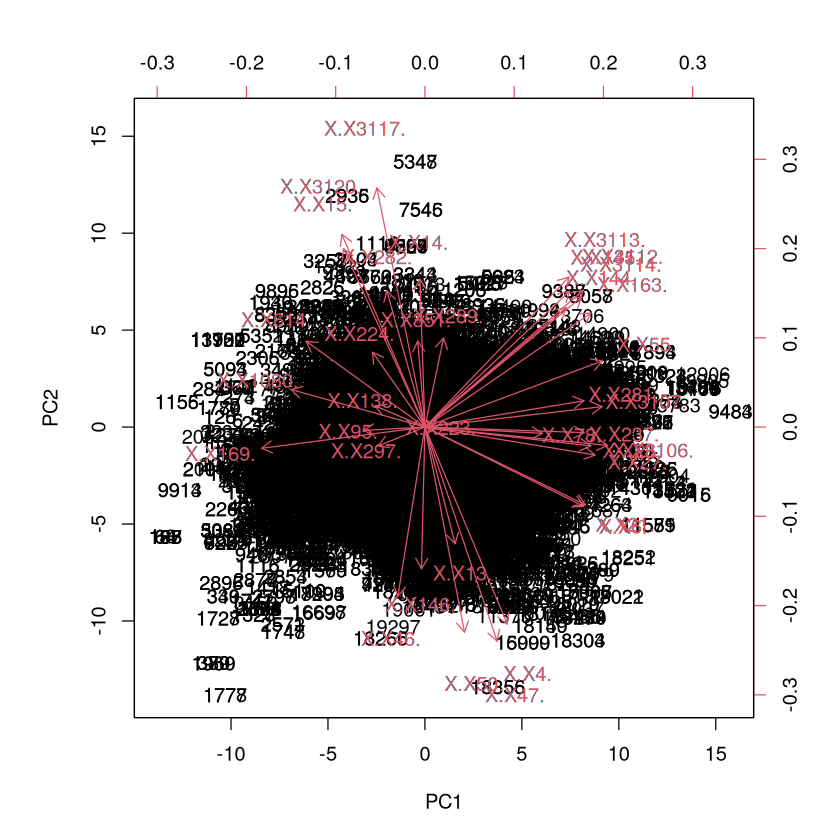

In [38]:
# Load other packages
library(ggplot2)
library(tidyr)
# Load dplyr last
library(dplyr)


# Perform PCA on the filtered and imputed mean trait data
pca_result <- prcomp(gbif_imputed %>% dplyr::select(starts_with("X")), center = TRUE, scale. = TRUE)
biplot(pca_result, scale = 0)


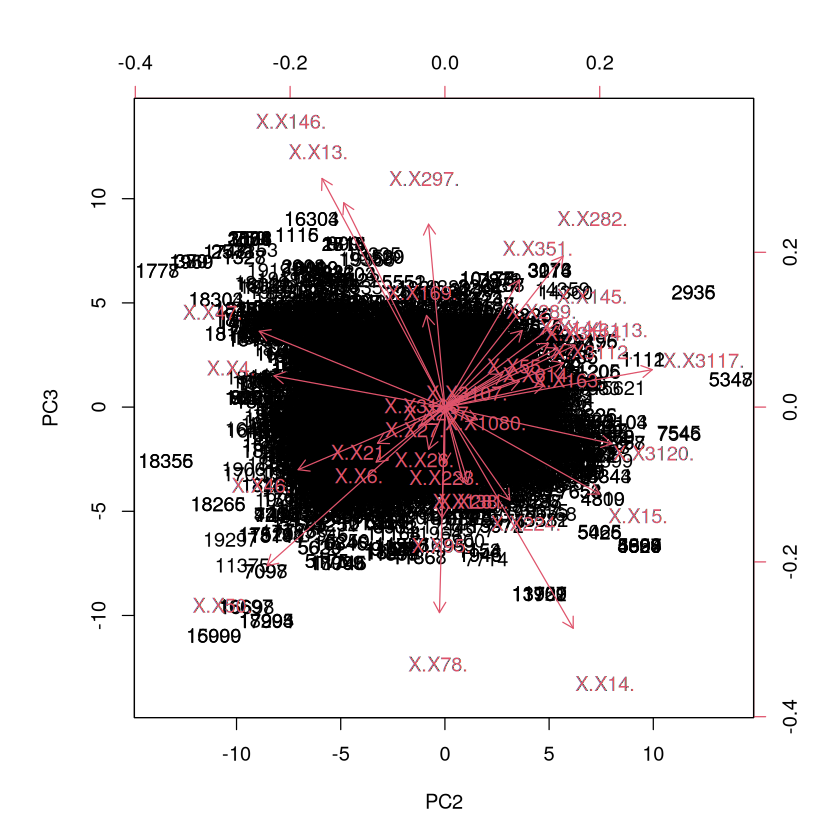

In [39]:
biplot(pca_result, choices = c(2, 3), scale = 0)


In [40]:
loadings <- pca_result$rotation   # traits × PCs


In [42]:
contrib <- sweep(loadings^2, 2, colSums(loadings^2), FUN = "/") * 100


Welcome! Want to learn more? See two factoextra-related books at https://goo.gl/ve3WBa



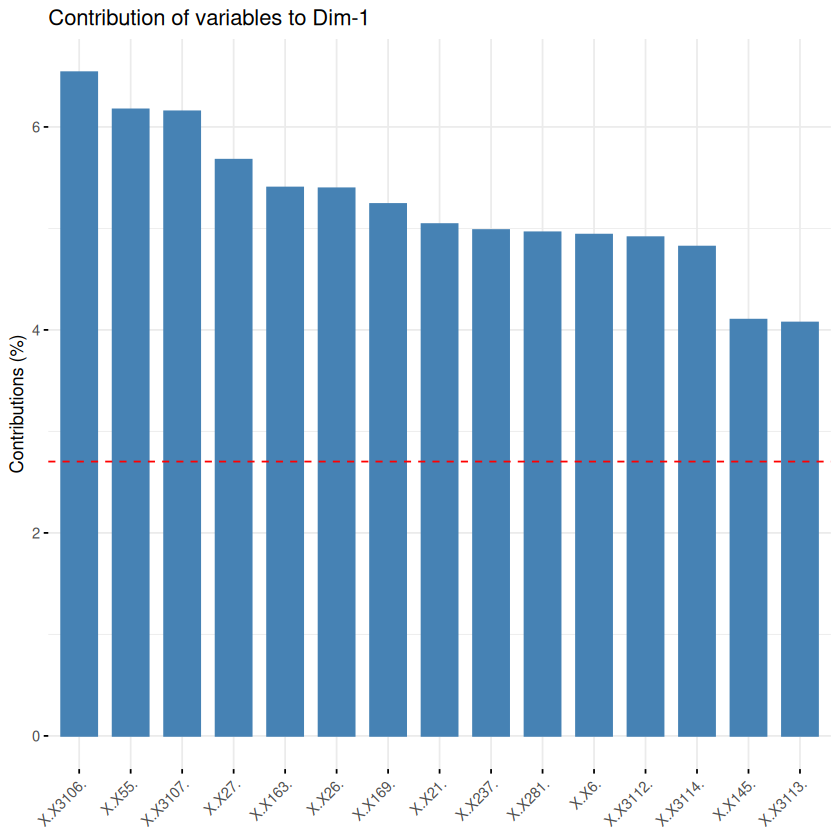

In [43]:
library(factoextra)

fviz_contrib(pca_result, choice = "var", axes = 1, top = 15)


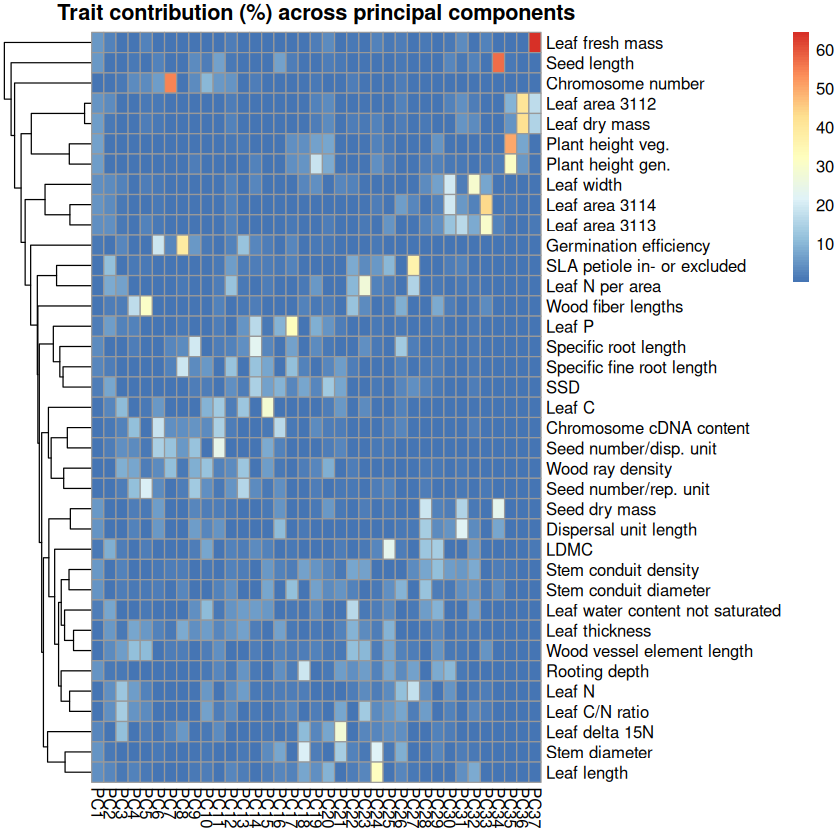

In [46]:
library(pheatmap)

pheatmap(contrib,
         cluster_rows = TRUE,
         cluster_cols = FALSE,
         scale = "none",
         display_numbers = FALSE,
         main = "Trait contribution (%) across principal components")


In [41]:
# read ~/Func_Neo_Phytes/Data/trait_info.csv
trait_info <- fread("/net/home/swolf/Func_Neo_Phytes/Data/trait_info.csv") 
head(trait_info)

TraitID,TraitID_TRY6,TraitName,ShortName,sPlotOpenName,UnitName
<int>,<chr>,<chr>,<chr>,<chr>,<chr>
4,X.X4.,"Stem specific density (SSD, stem dry mass per stem fresh volume) or wood density",SSD,SSD,g/cm3
6,X.X6.,Root rooting depth,Rooting depth,,m
13,X.X13.,Leaf carbon (C) content per leaf dry mass,Leaf C,Leaf.C,mg/g
14,X.X14.,Leaf nitrogen (N) content per leaf dry mass,Leaf N,Leaf.N.per.mass,mg/g
15,X.X15.,Leaf phosphorus (P) content per leaf dry mass,Leaf P,Leaf.P,mg/g
21,X.X21.,Stem diameter,Stem diameter,,m


In [44]:
# Set row names of contrib to "ShortName" from trait_info
rownames(contrib) <- trait_info$ShortName[match(rownames(contrib), trait_info$TraitID_TRY6)]

pdf 
  2

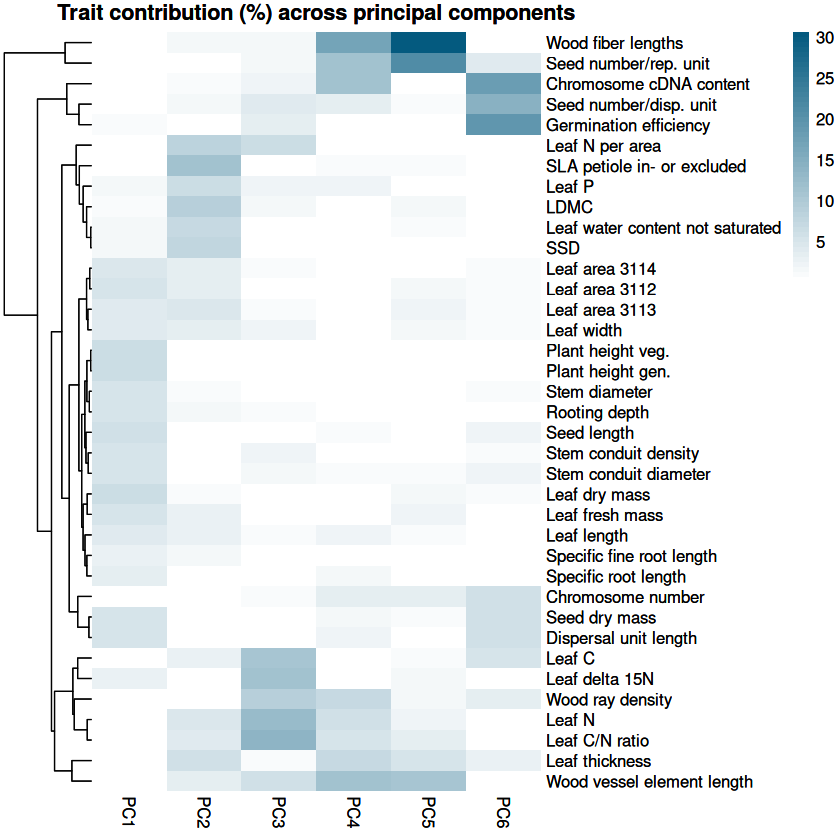

In [48]:

final_plot <- pheatmap(contrib[, 1:6],
         cluster_rows = TRUE,
         cluster_cols = FALSE,
         scale = "none",
         display_numbers = FALSE,
         main = "Trait contribution (%) across principal components",
         color = colorRampPalette(c("#FFFFFF", "#045A7FFF"))(50),
         border_color = NA)

png(file = "~/Func_Neo_Phytes/Results/Figures/trait_contribution_heatmap_no_border_1-6_angio.png", width = 6, height = 7, units = "in", res = 300)

print(final_plot)
dev.off()

print(final_plot)


In [50]:
# filter contrib for PC1, PC2, PC3 with values greater than 5
contrib_filtered <- contrib[apply(contrib[, 1:3], 1, function(x) any(x > 5)), 1:3]  

pdf 
  2

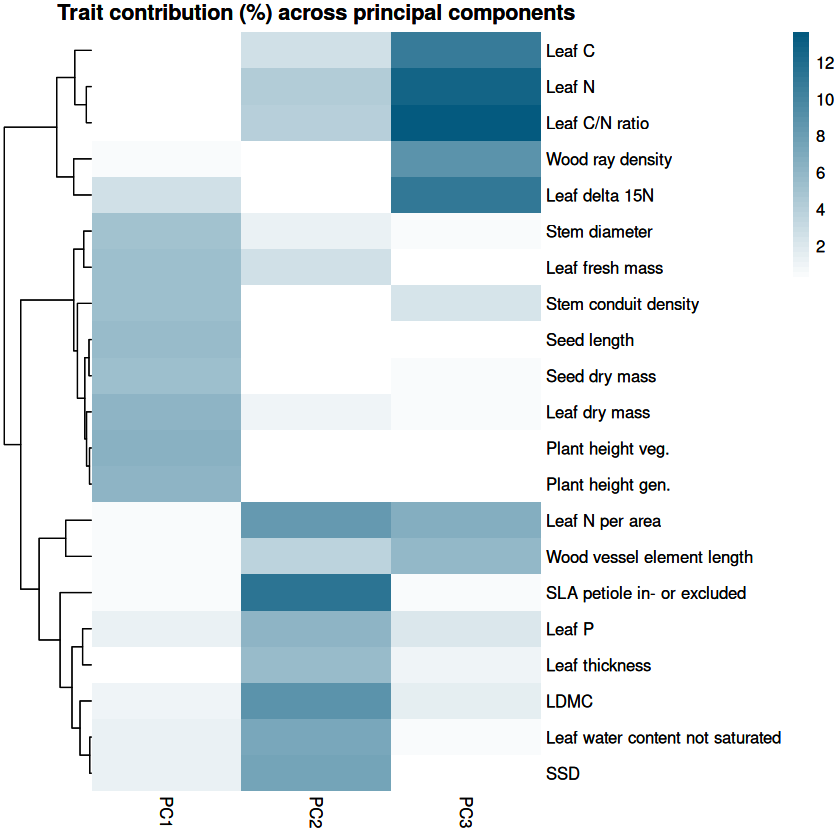

In [51]:
final_plot <- pheatmap(contrib_filtered[, 1:3],
         cluster_rows = TRUE,
         cluster_cols = FALSE,
         scale = "none",
         display_numbers = FALSE,
         main = "Trait contribution (%) across principal components",
         color = colorRampPalette(c("#FFFFFF", "#045A7FFF"))(50),
         border_color = NA)

png(file = "~/Func_Neo_Phytes/Results/Figures/trait_contribution_heatmap_masked_1-3_angio.png", width = 6, height = 7, units = "in", res = 300)

print(final_plot)
dev.off()

print(final_plot)


In [ ]:
contrib_filtered


,PC1,PC2,PC3
SLA petiole in- or excluded,0.3510026417,11.31566720,0.480662213
Leaf N,0.0004513781,4.85014546,12.602077281
Leaf N per area,0.2477494351,7.83390205,7.209851114
Leaf C/N ratio,0.0213138988,4.44103294,13.494173004
Leaf water content not saturated,1.2545713592,7.71993069,0.126263281
Wood ray density,0.3735685991,0.08814101,5.518551914
Leaf C,0.1026853029,3.22010729,10.072926578
Leaf P,1.2198585224,6.48220951,1.402777033
Leaf area 3114,5.0572660538,3.03065519,0.838432117
Leaf area 3112,5.1312932316,3.40407145,0.475010830


In [ ]:
#pca_result$rotation[, "PC3"] <- -pca_result$rotation[, "PC3"]


In [52]:
trait_pca <- as.data.frame(pca_result$rotation)
trait_pca$trait <- rownames(trait_pca)
rownames(trait_pca) <- NULL



In [53]:
# save trait_pca to file
fwrite(trait_pca, "/net/scratch/swolf/GBIF/trait_pca_glonaf_wcvp_res3_try6_mean_imp_CS_log10_angio.csv")

### Variance explained by each axis


[1] 0.60752


pdf 
  2

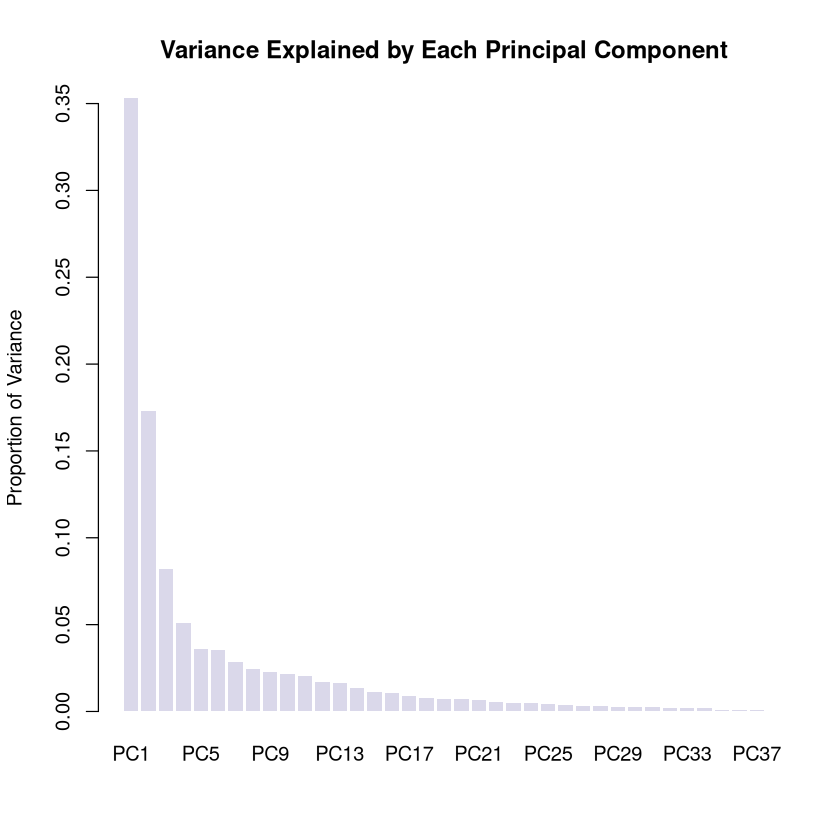

In [ ]:

# Variance explained by each PC
explained_variance <- summary(pca_result)$importance[2,]

# sum of variance explained by first 3 PCs
print(sum(explained_variance[1:3]))

pdf(
  #file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_global_var_explained.pdf"), 
  file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_global_var_explained_GBIF_wcvp_CS_log10.pdf"), 
  #file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_global_var_explained_GBIF_wcvp_CS_n100.pdf"), 
  width = 10,  # Width in inches
  height = 7   # Height in inches
)
barplot(explained_variance, main = "Variance Explained by Each Principal Component", 
        col = "#dad8eaff", ylab = "Proportion of Variance", border = NA)

dev.off()

# Print the barplot to the screen
barplot(explained_variance, main = "Variance Explained by Each Principal Component", 
        col = "#dad8eaff", ylab = "Proportion of Variance", border = NA)



pdf 
  2

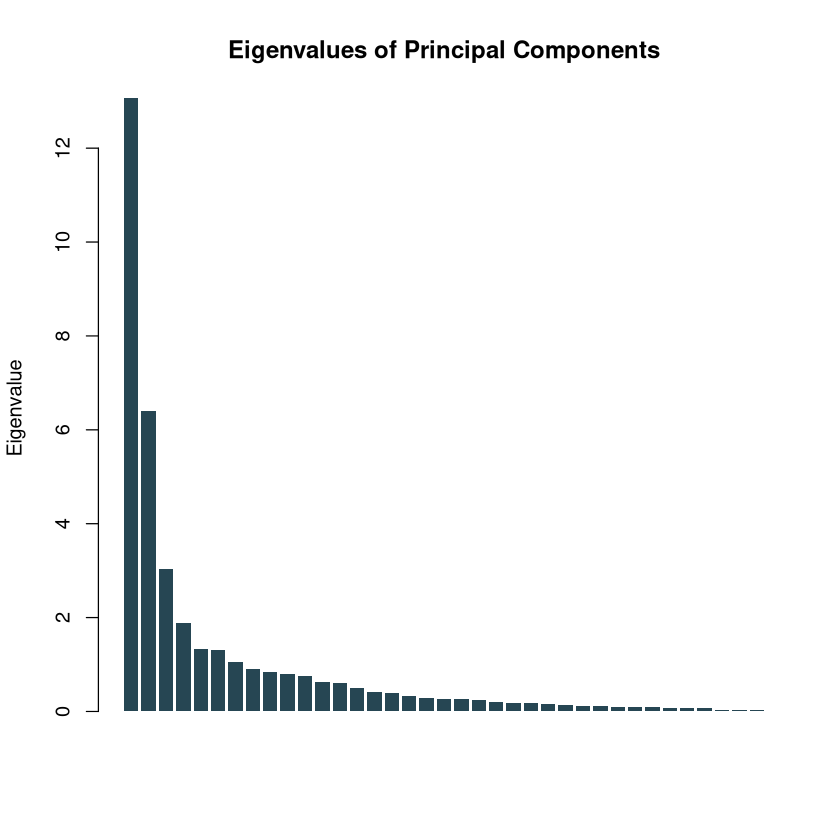

In [ ]:
# plot the eigenvalues
eigenvalues <- pca_result$sdev^2
pdf(
  file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_global_eigenvalues_wcvp_CS_log10.pdf"), 
  #file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_global_eigenvalues_wcvp_CS_n100.pdf"), 

  width = 10,  # Width in inches
  height = 7   # Height in inches
)       
barplot(eigenvalues, main = "Eigenvalues of Principal Components", 
        col = "#264653", ylab = "Eigenvalue", border = NA)  

dev.off()
barplot(eigenvalues, main = "Eigenvalues of Principal Components", 
        col = "#264653", ylab = "Eigenvalue", border = NA)  



In [ ]:
explained_variance

PC1     PC2     PC3     PC4     PC5     PC6     PC7     PC8     PC9    PC10 
0.35297 0.17275 0.08180 0.05105 0.03605 0.03517 0.02867 0.02461 0.02292 0.02161 
   PC11    PC12    PC13    PC14    PC15    PC16    PC17    PC18    PC19    PC20 
0.02024 0.01687 0.01647 0.01352 0.01136 0.01048 0.00907 0.00791 0.00720 0.00700 
   PC21    PC22    PC23    PC24    PC25    PC26    PC27    PC28    PC29    PC30 
0.00661 0.00555 0.00506 0.00491 0.00412 0.00363 0.00305 0.00295 0.00277 0.00254 
   PC31    PC32    PC33    PC34    PC35    PC36    PC37 
0.00242 0.00215 0.00208 0.00183 0.00107 0.00094 0.00060

[1] 0.60366


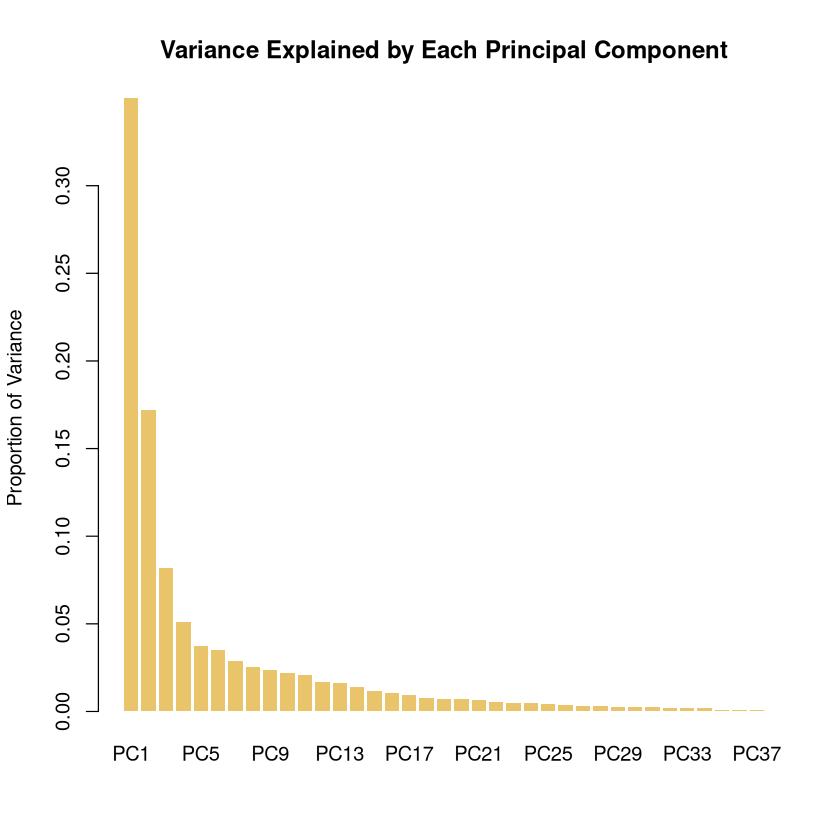

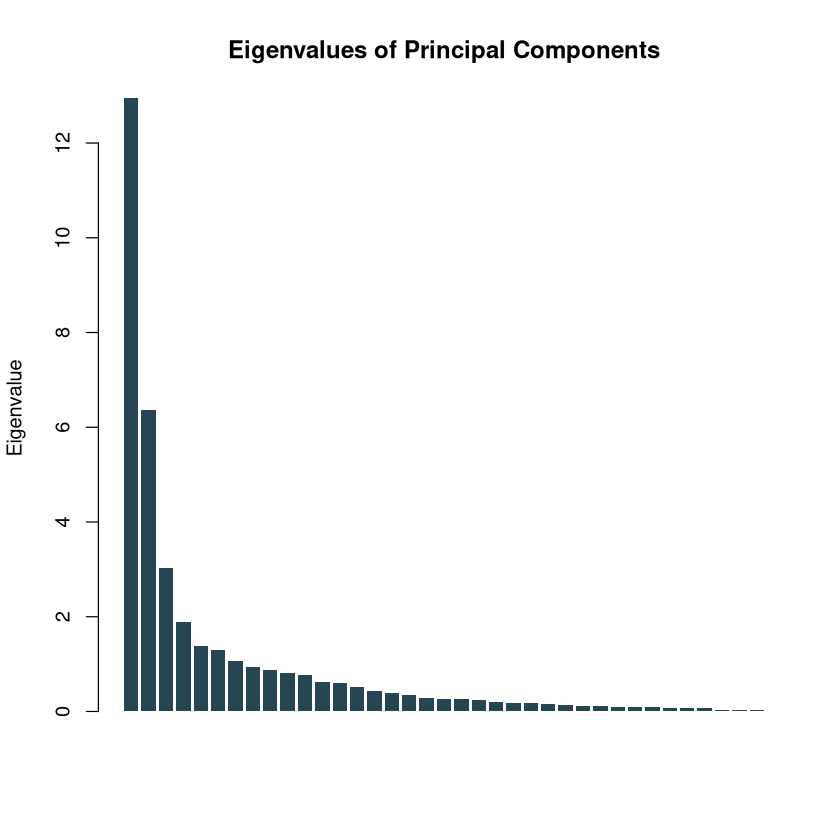

In [ ]:
# filter gbif_imputed for group == "native"
gbif_imputed_native <- gbif_imputed %>%
  filter(group == "native") 

# and perform PCA again
pca_result_native <- prcomp(gbif_imputed_native %>% dplyr::select(starts_with("X")), center = TRUE, scale. = TRUE)

# Variance explained by each PC
explained_variance_native <- summary(pca_result_native)$importance[2,] 
# sum of variance explained by first 3 PCs
print(sum(explained_variance_native[1:3])) 

# Print the barplot to the screen
barplot(explained_variance_native, main = "Variance Explained by Each Principal Component", 
        col = "#e9c46a", ylab = "Proportion of Variance", border = NA)

eigenvalues_native <- pca_result_native$sdev^2
barplot(eigenvalues_native, main = "Eigenvalues of Principal Components", 
        col = "#264653", ylab = "Eigenvalue", border = NA)  


[1] 0.60366


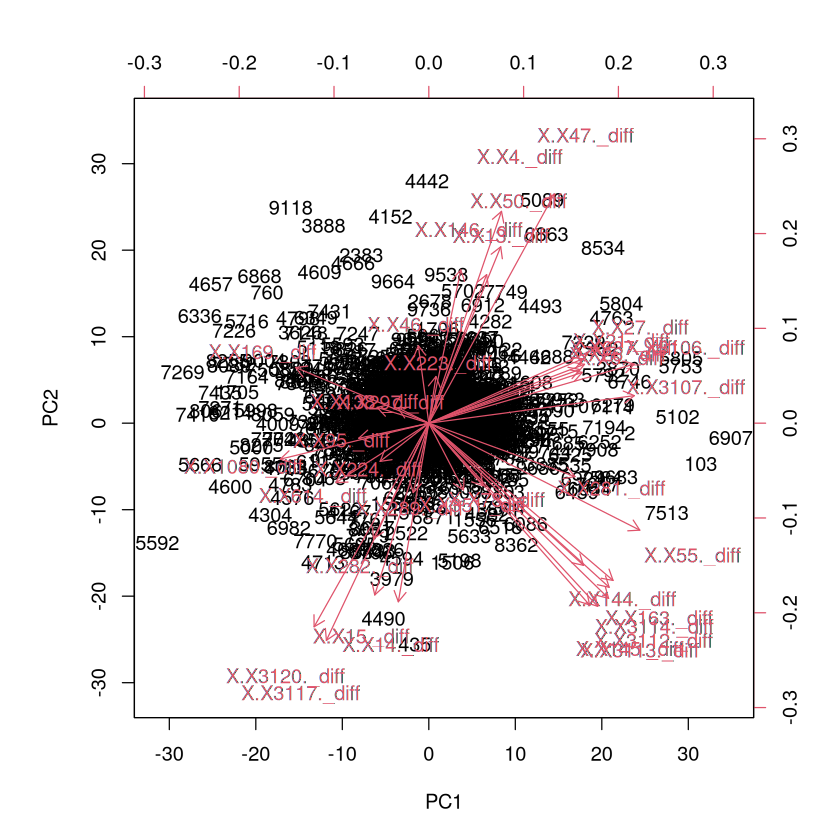

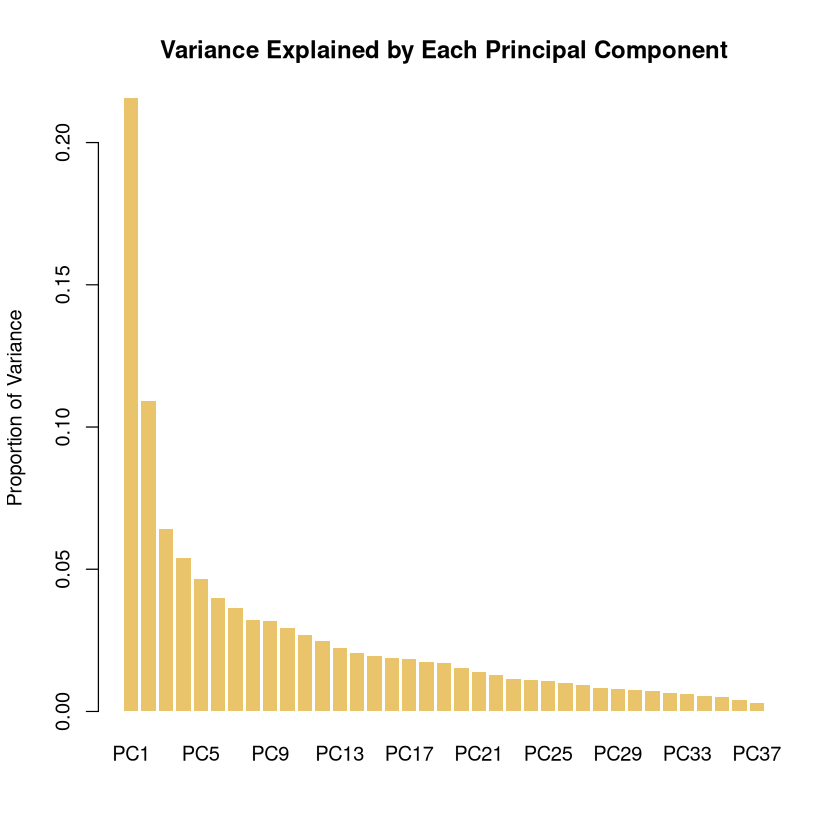

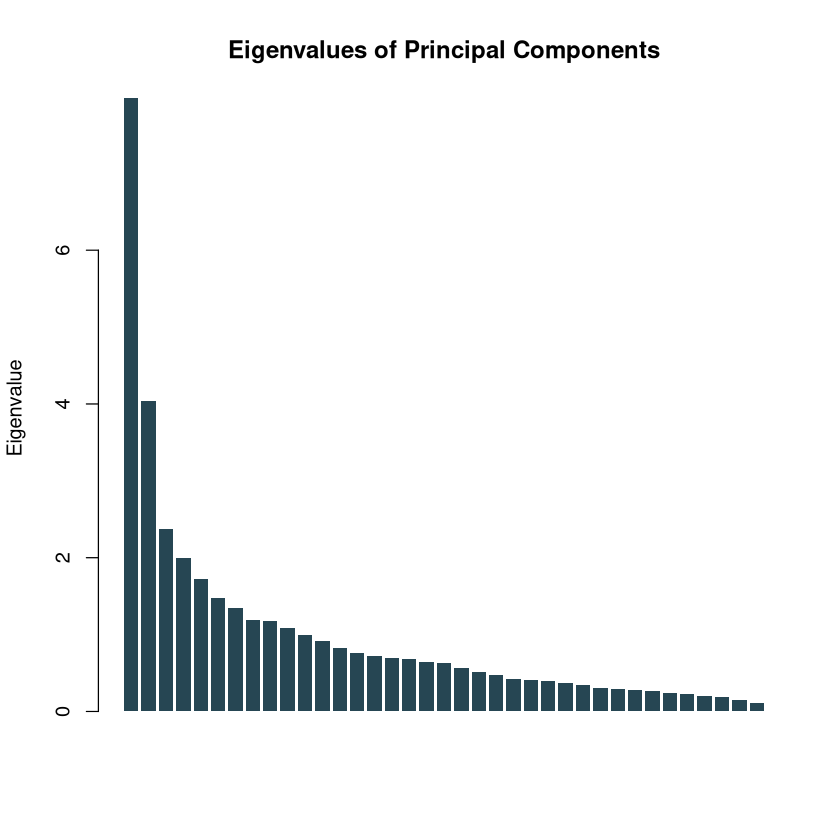

In [ ]:

# and perform PCA again
pca_result_diff <- prcomp(gbif_diff %>% dplyr::select(starts_with("X")), center = TRUE, scale. = TRUE)

# Variance explained by each PC
explained_variance_diff <- summary(pca_result_diff)$importance[2,] 
biplot(pca_result_diff <- prcomp(gbif_diff %>% dplyr::select(starts_with("X")), center = TRUE, scale. = TRUE)
, scale = 0)
# sum of variance explained by first 3 PCs
print(sum(explained_variance_native[1:3])) 

# Print the barplot to the screen
barplot(explained_variance_diff, main = "Variance Explained by Each Principal Component", 
        col = "#e9c46a", ylab = "Proportion of Variance", border = NA)

eigenvalues_diff <- pca_result_diff$sdev^2
barplot(eigenvalues_diff, main = "Eigenvalues of Principal Components", 
        col = "#264653", ylab = "Eigenvalue", border = NA)  


[1] 0.61151


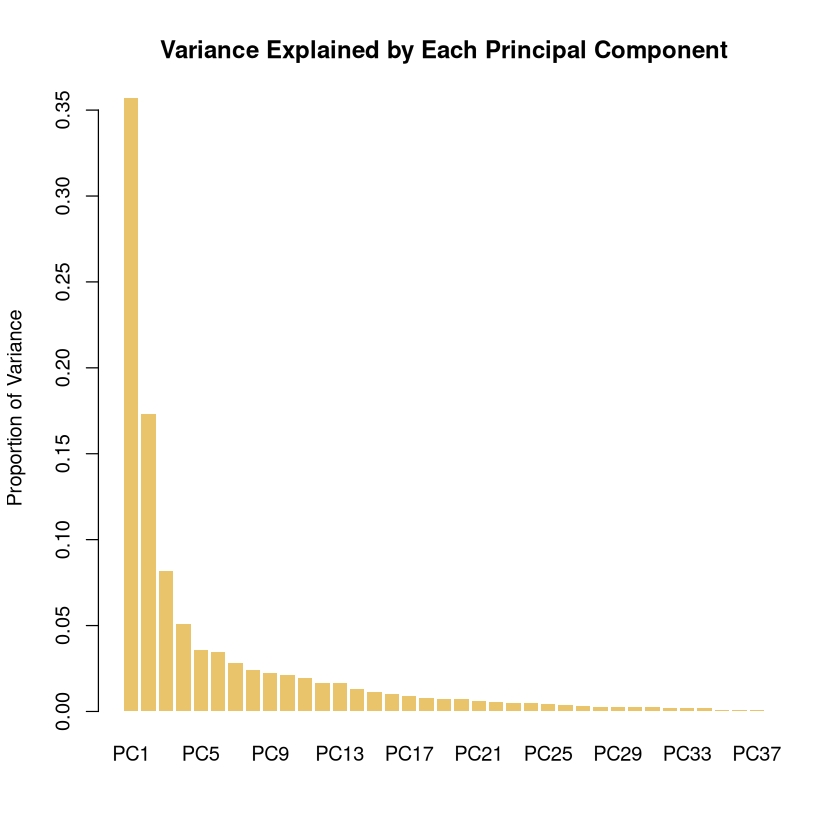

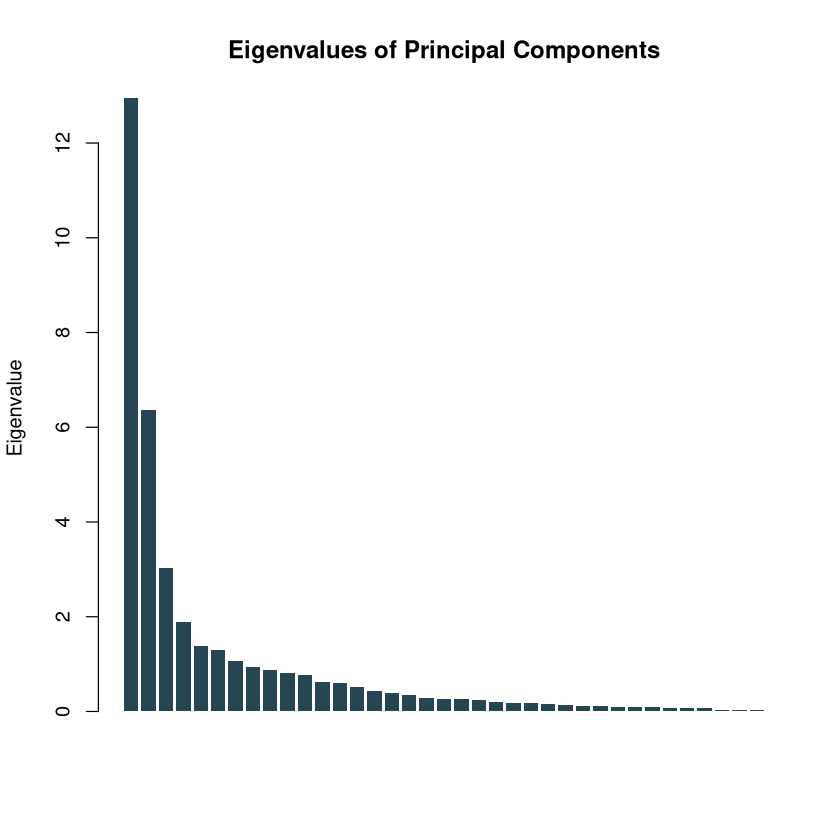

In [ ]:
# filter gbif_imputed for group == "native"
gbif_imputed_all <- gbif_imputed %>%
  filter(group == "all") 

# and perform PCA again
pca_result_all <- prcomp(gbif_imputed_all %>% dplyr::select(starts_with("X")), center = TRUE, scale. = TRUE)

# Variance explained by each PC
explained_variance_all <- summary(pca_result_all)$importance[2,] 
# sum of variance explained by first 3 PCs
print(sum(explained_variance_all[1:3])) 

# Print the barplot to the screen
barplot(explained_variance_all, main = "Variance Explained by Each Principal Component", 
        col = "#e9c46a", ylab = "Proportion of Variance", border = NA)

eigenvalues_all <- pca_result_native$sdev^2
barplot(eigenvalues_all, main = "Eigenvalues of Principal Components", 
        col = "#264653", ylab = "Eigenvalue", border = NA)  


In [54]:
library(data.table)

# Flip PC1
pca_scores <- data.table(
  h3_res3 = gbif_imputed$h3_res3,
  group = gbif_imputed$group,  # "all" or "native"
  PC1 = pca_result$x[, 1],  # flip the sign of PC1 for GBIF_glonaf, GBIF_glonaf_wcvp_woody, GBIF_glonaf_wcvp_nonwoody
  PC2 = pca_result$x[, 2],   # flip the sign of PC2 for GBIF_glonaf_wcvp_all
  PC3 = pca_result$x[, 3],
  PC4 = pca_result$x[, 4]
  # no flip for CS only

)
head(pca_scores)

h3_res3,group,PC1,PC2,PC3,PC4
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
83001afffffffff,native,-11.09230939,-0.2152630,-0.7468986,0.6183459
83001afffffffff,all,-11.09129392,-0.2148544,-0.7514684,0.6225289
83001cfffffffff,native,0.01974138,-0.1170907,0.1095429,0.0434351
83001cfffffffff,all,-8.59865051,-0.2075157,-0.7648746,3.3157436
83001efffffffff,native,-9.65589980,0.3251902,-1.3987962,1.7547944
83001efffffffff,all,-9.64707398,0.3273703,-1.4286388,1.7698961


In [55]:
# Reshape from long to wide format
pca_scores_wide <- dcast(pca_scores, h3_res3 ~ group, value.var = c("PC1", "PC2", "PC3", "PC4"))
head(pca_scores_wide)

h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
83001afffffffff,-11.091294,-11.09230939,-0.2148544,-0.2152630,-0.7514684,-0.7468986,0.6225289,0.6183459
83001cfffffffff,-8.598651,0.01974138,-0.2075157,-0.1170907,-0.7648746,0.1095429,3.3157436,0.0434351
83001efffffffff,-9.647074,-9.65589980,0.3273703,0.3251902,-1.4286388,-1.3987962,1.7698961,1.7547944
830025fffffffff,-9.807919,-9.80791863,1.1309281,1.1309281,-2.0533489,-2.0533489,-0.1963549,-0.1963549
830028fffffffff,-8.987000,-8.98700028,-1.8104180,-1.8104180,-0.9850796,-0.9850796,0.2075176,0.2075176
830029fffffffff,-9.274945,-9.27494479,-1.1911312,-1.1911312,-1.1286106,-1.1286106,1.3171998,1.3171998


In [56]:
# Compute percent change
pca_scores_wide[, `:=`(
  PC1_percent_change = ((PC1_all - PC1_native) / abs(PC1_native)) * 100,
  PC2_percent_change = ((PC2_all - PC2_native) / abs(PC2_native)) * 100
)]

# Step 2: Join the pca_scores with gbif_down by 'gbifID'
gbif_summary <- pca_scores_wide[gbif_summary, on = "h3_res3"]
head(gbif_summary)

h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC1_percent_change,⋯,X.X78..median_native,X.X78..percent_change_mean,X.X78..percent_change_median,X.X4..mean_all,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,resolution
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
832830fffffffff,-1.8606853,-1.39747711,0.9012810,0.2112816,-0.04055756,0.5272968,-0.3931795,-0.6497072,-33.146031,⋯,-0.862,56.31,45.59,0.441,0.471,0.430,0.459,-6.37,-6.32,h3_res3
832834fffffffff,-1.8623921,-1.33173863,0.5599171,-0.2153165,0.02031236,0.6106718,-0.6344336,-0.8890877,-39.846671,⋯,-0.969,48.02,25.80,0.452,0.479,0.445,0.470,-5.64,-5.32,h3_res3
832831fffffffff,-2.0233401,-1.66926601,0.9665454,0.6089913,0.40753700,0.8361863,-0.1013847,-0.2993076,-21.211367,⋯,-1.141,41.04,26.29,0.441,0.461,0.430,0.458,-4.34,-6.11,h3_res3
832655fffffffff,-0.2905035,0.06196313,2.5221667,2.4199037,0.53362559,0.9996922,-0.3003657,-0.1051773,-568.832759,⋯,-0.269,95.39,7.06,0.438,0.448,0.435,0.438,-2.23,-0.68,h3_res3
832a16fffffffff,-0.9125733,-0.31232126,3.1592074,3.0873603,0.76356215,1.9953716,-0.5803780,-0.6846020,-192.190594,⋯,-0.869,61.53,62.83,0.424,0.444,0.411,0.437,-4.50,-5.95,h3_res3
8329a5fffffffff,-1.7297192,-1.61779246,-0.4908029,-1.6351966,-1.19749909,-0.6877529,-0.3198007,-0.6037101,-6.918487,⋯,-0.039,73.78,1010.26,0.460,0.485,0.465,0.478,-5.15,-2.72,h3_res3


In [57]:
#fwrite(gbif_summary, "/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_summary_stats_inkl_pca_mean.csv", row.names = F, quote = T)
#fwrite(gbif_summary, "/net/scratch/swolf/GBIF/gbif_res3_try6_CS_summary_stats_inkl_pca_mean.csv", row.names = F, quote = T)
#fwrite(gbif_summary, "/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_wcvp_all_summary_stats_inkl_pca_mean.csv", row.names = F, quote = T)
#fwrite(gbif_summary, "/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_wcvp_woody_summary_stats_inkl_pca_mean.csv", row.names = F, quote = T)
#fwrite(gbif_summary, "/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_wcvp_nonwoody_summary_stats_inkl_pca_mean.csv", row.names = F, quote = T)
#fwrite(gbif_summary, "/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean.csv", row.names = F, quote = T)

fwrite(gbif_summary, "/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10_angio.csv", row.names = F, quote = T)
#fwrite(gbif_summary, "/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_n100.csv", row.names = F, quote = T)


In [58]:

head(pca_scores)
head(gbif_average_wide)
setDT(pca_scores)
setDT(gbif_average_wide)
# Step 2: Join the pca_scores with gbif by hexagon id
gbif_summary2 <- pca_scores[gbif_average_wide, on = c("h3_res3", "group")]
head(gbif_summary2)

h3_res3,group,PC1,PC2,PC3,PC4
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
83001afffffffff,native,-11.09230939,-0.2152630,-0.7468986,0.6183459
83001afffffffff,all,-11.09129392,-0.2148544,-0.7514684,0.6225289
83001cfffffffff,native,0.01974138,-0.1170907,0.1095429,0.0434351
83001cfffffffff,all,-8.59865051,-0.2075157,-0.7648746,3.3157436
83001efffffffff,native,-9.65589980,0.3251902,-1.3987962,1.7547944
83001efffffffff,all,-9.64707398,0.3273703,-1.4286388,1.7698961


h3_res3,group,count,X.X3117.,X.X14.,X.X50.,X.X146.,X.X3120.,X.X224.,X.X297.,⋯,X.X223.,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
832830fffffffff,all,525930,18.415,23.107,1.510,23.548,4.836,0.512,0.990,⋯,27.297,0.516,3.568,0.076,-0.434,89.797,2.432,3.431,-0.374,0.441
832830fffffffff,native,370050,16.593,21.804,1.542,24.913,4.422,0.496,0.987,⋯,27.223,0.532,3.536,0.097,-0.397,88.692,2.370,3.375,-0.856,0.471
832834fffffffff,all,439943,18.223,22.759,1.536,23.790,4.682,0.496,1.001,⋯,27.278,0.523,3.561,0.076,-0.417,89.831,2.450,3.418,-0.459,0.452
832834fffffffff,native,325248,16.205,21.529,1.562,25.006,4.302,0.478,1.003,⋯,27.321,0.545,3.534,0.093,-0.364,88.816,2.376,3.346,-0.883,0.479
832831fffffffff,all,62389,18.910,22.240,1.410,24.216,4.902,0.507,0.995,⋯,27.538,0.512,3.577,0.075,-0.439,89.465,2.451,3.415,-0.615,0.441
832831fffffffff,native,49599,17.914,21.274,1.417,25.397,4.705,0.503,0.999,⋯,27.596,0.534,3.547,0.089,-0.421,88.967,2.384,3.366,-1.043,0.461


h3_res3,group,PC1,PC2,PC3,PC4,count,X.X3117.,X.X14.,X.X50.,⋯,X.X223.,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
832830fffffffff,all,-1.860685,0.9012810,-0.04055756,-0.3931795,525930,18.415,23.107,1.510,⋯,27.297,0.516,3.568,0.076,-0.434,89.797,2.432,3.431,-0.374,0.441
832830fffffffff,native,-1.397477,0.2112816,0.52729682,-0.6497072,370050,16.593,21.804,1.542,⋯,27.223,0.532,3.536,0.097,-0.397,88.692,2.370,3.375,-0.856,0.471
832834fffffffff,all,-1.862392,0.5599171,0.02031236,-0.6344336,439943,18.223,22.759,1.536,⋯,27.278,0.523,3.561,0.076,-0.417,89.831,2.450,3.418,-0.459,0.452
832834fffffffff,native,-1.331739,-0.2153165,0.61067179,-0.8890877,325248,16.205,21.529,1.562,⋯,27.321,0.545,3.534,0.093,-0.364,88.816,2.376,3.346,-0.883,0.479
832831fffffffff,all,-2.023340,0.9665454,0.40753700,-0.1013847,62389,18.910,22.240,1.410,⋯,27.538,0.512,3.577,0.075,-0.439,89.465,2.451,3.415,-0.615,0.441
832831fffffffff,native,-1.669266,0.6089913,0.83618630,-0.2993076,49599,17.914,21.274,1.417,⋯,27.596,0.534,3.547,0.089,-0.421,88.967,2.384,3.366,-1.043,0.461


In [59]:

#fwrite(gbif_summary2, "/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_summary_stats_inkl_pca_mean_group.csv", row.names = F, quote = T)
#fwrite(gbif_summary2, "/net/scratch/swolf/GBIF/gbif_res3_try6_CS_summary_stats_inkl_pca_mean_group.csv", row.names = F, quote = T)

fwrite(gbif_summary2, "/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_log10_angio.csv", row.names = F, quote = T)

#fwrite(gbif_summary2, "/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_wcvp_all_summary_stats_inkl_pca_mean_group.csv", row.names = F, quote = T)
#fwrite(gbif_summary2, "/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_wcvp_woody_summary_stats_inkl_pca_mean_group.csv", row.names = F, quote = T)
#fwrite(gbif_summary2, "/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_wcvp_nonwoody_summary_stats_inkl_pca_mean_group.csv", row.names = F, quote = T)


## Flow Field

In [ ]:
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

# read /net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean.csv
gbif_summary <- fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10.csv")

head(gbif_summary)

h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC1_percent_change,⋯,X.X78..median_native,X.X78..percent_change_mean,X.X78..percent_change_median,X.X4..mean_all,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,resolution
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
832830fffffffff,-1.8038341,-1.35482967,0.9603752,0.1581176,-0.05605286,-0.6131218,0.28704004,0.47782598,-33.141024,⋯,-0.864,55.17,44.21,0.442,0.471,0.430,0.461,-6.16,-6.72,h3_res3
832834fffffffff,-1.7814382,-1.29902183,0.5006442,-0.2982885,-0.16618360,-0.6990300,0.48394999,0.65921448,-37.136897,⋯,-0.970,46.71,23.30,0.453,0.478,0.449,0.471,-5.23,-4.67,h3_res3
832831fffffffff,-1.9763540,-1.59160415,0.9112940,0.3624014,-0.61732579,-1.1252867,-0.06457907,0.03630553,-24.173716,⋯,-1.237,39.56,32.01,0.442,0.460,0.437,0.458,-3.91,-4.59,h3_res3
832655fffffffff,-0.2605628,0.07481552,2.5676102,2.4014114,-0.61717831,-1.1149993,0.40472226,0.25530429,-448.273661,⋯,-0.276,86.05,9.42,0.438,0.448,0.435,0.438,-2.23,-0.68,h3_res3
832a16fffffffff,-0.8424427,-0.25877041,2.9200629,2.5958144,-0.88607992,-2.1060823,0.45917662,0.57860174,-225.556026,⋯,-0.860,56.99,61.86,0.423,0.442,0.406,0.426,-4.30,-4.69,h3_res3
8329a5fffffffff,-1.7371124,-1.63955304,-0.2342676,-1.3958365,1.27144386,0.8847160,0.20159946,0.53819018,-5.950362,⋯,-0.039,73.33,979.49,0.460,0.485,0.465,0.478,-5.15,-2.72,h3_res3


Warning message:
“The dot-dot notation (`..index..`) was deprecated in ggplot2 3.4.0.
ℹ Please use `after_stat(index)` instead.”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Native → All' in 'mbcsToSbcs': -> substituted for → (U+2192)”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“for 'Community Hex Links in PCA Space — All Regions' in 'mbcsToSbcs': - substituted for — (U+2014)”


pdf 
  2

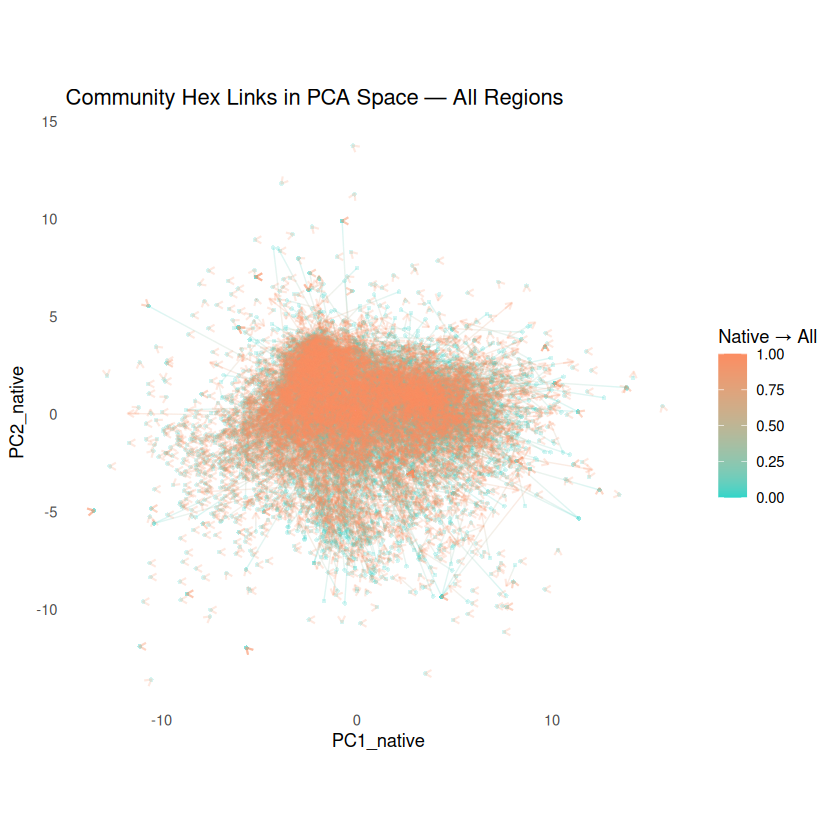

In [ ]:
library(ggplot2)
library(ggforce)
library(dplyr)
library(grid)  # for arrow()

plot_gradient_links <- function(data, region_code) {
  color_native <- "#2ed5c9"
  color_all <- "#fc8d62"

  arrow_df <- data %>%
    rowwise() %>%
    mutate(
      dx = PC1_all - PC1_native,
      dy = PC2_all - PC2_native,
      arrow_xstart = PC1_all - 0.05 * dx,
      arrow_ystart = PC2_all - 0.05 * dy,
      arrow_xend = PC1_all,
      arrow_yend = PC2_all
    ) %>%
    ungroup()

  p <- ggplot(data) +
    geom_link(
      aes(x = PC1_native, y = PC2_native,
          xend = PC1_all, yend = PC2_all,
          color = ..index..),
      linewidth = 0.4,
      alpha = 0.2
    ) +
    geom_point(
      aes(x = PC1_native, y = PC2_native),
      color = color_native,
      size = 1,
      shape = 16,
      alpha = 0.2
    ) +
    geom_segment(
      data = arrow_df,
      aes(x = arrow_xstart, y = arrow_ystart,
          xend = arrow_xend, yend = arrow_yend),
      color = color_all,
      linewidth = 0.6,
      alpha = 0.2,
      arrow = arrow(length = unit(0.06, "inches"), type = "open")
    ) +
    scale_color_gradient(low = color_native, high = color_all) +
    coord_equal() +
     theme_minimal() +
    theme(
      panel.grid = element_blank(),
      legend.position = "right"
    ) +
    labs(color = "Native → All") +
    ggtitle(paste("Community Hex Links in PCA Space —", region_code))

  return(p)
}


# Create the plot with gradient links for all gbif_summary data together
combined_plot <- plot_gradient_links(gbif_summary, "All Regions")

# Save to PDF
pdf(file = "~/Func_Neo_Phytes/Results/Figures/gradient_links_GBIF_CS_wcvp_all_regions_log10.pdf",
    width = 10, height = 7)
print(combined_plot)
dev.off()

# Optionally print on screen too
print(combined_plot)


## Plot global PCA

I added PCA for wcvp version already in summary_stats.ipynb

In [ ]:

#gbif_summary <- fread("/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_summary_stats_inkl_pca_mean.csv")
#gbif_summary <- fread("/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_res3_try6_s1_5000_summary_stats_all_inkl_pca_mean.csv")

head(gbif_summary)


h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC1_percent_change,⋯,X.X78..median_native,X.X78..percent_change_mean,X.X78..percent_change_median,X.X4..mean_all,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,resolution
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
832830fffffffff,-1.8038341,-1.35482967,0.9603752,0.1581176,-0.05605286,-0.6131218,0.28704004,0.47782598,-33.141024,⋯,-0.864,55.17,44.21,0.442,0.471,0.430,0.461,-6.16,-6.72,h3_res3
832834fffffffff,-1.7814382,-1.29902183,0.5006442,-0.2982885,-0.16618360,-0.6990300,0.48394999,0.65921448,-37.136897,⋯,-0.970,46.71,23.30,0.453,0.478,0.449,0.471,-5.23,-4.67,h3_res3
832831fffffffff,-1.9763540,-1.59160415,0.9112940,0.3624014,-0.61732579,-1.1252867,-0.06457907,0.03630553,-24.173716,⋯,-1.237,39.56,32.01,0.442,0.460,0.437,0.458,-3.91,-4.59,h3_res3
832655fffffffff,-0.2605628,0.07481552,2.5676102,2.4014114,-0.61717831,-1.1149993,0.40472226,0.25530429,-448.273661,⋯,-0.276,86.05,9.42,0.438,0.448,0.435,0.438,-2.23,-0.68,h3_res3
832a16fffffffff,-0.8424427,-0.25877041,2.9200629,2.5958144,-0.88607992,-2.1060823,0.45917662,0.57860174,-225.556026,⋯,-0.860,56.99,61.86,0.423,0.442,0.406,0.426,-4.30,-4.69,h3_res3
8329a5fffffffff,-1.7371124,-1.63955304,-0.2342676,-1.3958365,1.27144386,0.8847160,0.20159946,0.53819018,-5.950362,⋯,-0.039,73.33,979.49,0.460,0.485,0.465,0.478,-5.15,-2.72,h3_res3


In [61]:
print(mean(gbif_summary$PC1_percent_change, na.rm = TRUE, trim = 0.01))
print(mean(gbif_summary$PC2_percent_change, na.rm = TRUE, trim = 0.01))

[1] -6.476672
[1] 45.65636


Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”
Warning message:
“The dot-dot notation (`..level..`) was deprecated in ggplot2 3.4.0.
ℹ Please use `after_stat(level)` instead.”
Warning message:
“Removed 492 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 647 rows containing non-finite outside the scale range
(`stat_density()`).”


pdf 
  2

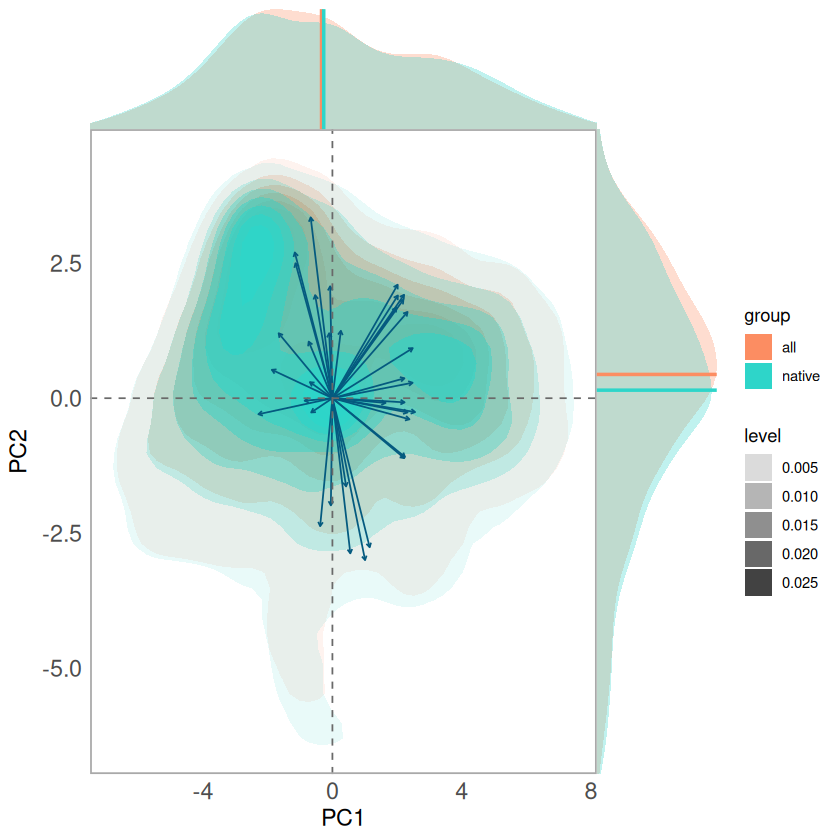

In [60]:
### Biplot with Loadings


# Load required libraries
library(ggplot2)
library(cowplot)
library(grid)
library(dplyr)

# Step 1: Perform PCA (already done)
# pca_result <- prcomp(gbif_imputed %>% dplyr::select(starts_with("X")), center = TRUE, scale. = TRUE)

# Step 2: Extract PCA scores
pca_scores <- as.data.frame(pca_result$x[, 1:2])  # PC1 and PC2
pca_scores$group <- gbif_imputed$group  # Adjust if your group column is named differently

# Step 3: Extract loadings and scale them
loadings <- as.data.frame(pca_result$rotation[, 1:2])  # PC1 and PC2
loadings$trait <- rownames(loadings)

arrow_scale <- 10  # Scale for arrow length (tweak if needed)
loadings <- loadings %>%
  mutate(PC1 = PC1 * arrow_scale,
         PC2 = PC2 * arrow_scale)

#flip PC1 gbif_glonaf_all, gbif_glonaf_wcvp_woody
#pca_scores$PC1 <- -pca_scores$PC1
#loadings$PC1 <- -loadings$PC1

#flip PC2 gbif_glonaf_wcvp_all
#pca_scores$PC2 <- -pca_scores$PC2
#loadings$PC2 <- -loadings$PC2


# Define absolute offset distance
label_offset <- 0.3  # adjust this value to control how far the label is from the arrow tip

# Compute arrow unit vectors
loadings <- loadings %>%
  mutate(
    arrow_length = sqrt(PC1^2 + PC2^2),
    unit_x = PC1 / arrow_length,
    unit_y = PC2 / arrow_length,
    label_x = PC1 + label_offset * unit_x,
    label_y = PC2 + label_offset * unit_y
  )

loadings$trait <- stringr::str_extract(loadings$trait, "\\d+")


# Create base plot without default group aesthetic
p <- ggplot(pca_scores, aes(x = PC1, y = PC2)) +
  stat_density_2d(data = pca_scores,
                  geom = "polygon", 
                  aes(alpha = ..level.., fill = group, group = group), 
                  bins = 10) +
  scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
  theme_minimal() +
    theme(panel.grid = element_blank(), legend.position = "right",
      axis.title = element_text(size = 14),  # Increase font size for axis labels
      axis.text = element_text(size = 14),  # Increase font size for axis numbers
      panel.border = element_rect(color = "darkgrey", fill = NA, linewidth = 1)) +  # Add box around plot
    theme(panel.grid = element_blank(), legend.position = "right") +
  geom_segment(data = loadings,
               aes(x = 0, y = 0, xend = PC1, yend = PC2),
               arrow = arrow(length = unit(0.1, "cm")),
               color = "#045A7FFF", size = 0.5) 
  #geom_text(data = loadings,
   #       aes(x = label_x, y = label_y, label = trait),
    #      color = "#2F86AC", size = 4, hjust = 0.5, vjust = 0.5)


  # Add grey line at 0,0
  p <- p +
    geom_hline(yintercept = 0, color = "dimgrey", linetype = "dashed") +
    geom_vline(xintercept = 0, color = "dimgrey", linetype = "dashed")
    
        # Step 5: Add marginal densities with median lines
        xdens <- axis_canvas(p, axis = "x") + 
            geom_density(data = pca_scores, aes(x = PC1, fill = group), 
                                     alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
            scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
            geom_vline(data = pca_scores %>% group_by(group) %>% summarise(median_PC1 = median(PC1, na.rm = TRUE)),
                                 aes(xintercept = median_PC1, color = group),
                                 linetype = "solid", size = 1) +
            scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9"))

        ydens <- axis_canvas(p, axis = "y", coord_flip = TRUE) + 
            geom_density(data = pca_scores, aes(x = PC2, fill = group), 
                                     alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
            scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
            geom_vline(data = pca_scores %>% group_by(group) %>% summarise(median_PC2 = median(PC2, na.rm = TRUE)),
                                 aes(xintercept = median_PC2, color = group),
                                 linetype = "solid", size = 1) +
            scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
            coord_flip()

# Step 6: Combine plot with marginal densities
final_plot <- p %>%
  insert_xaxis_grob(xdens, grid::unit(1, "in"), position = "top") %>%
  insert_yaxis_grob(ydens, grid::unit(1, "in"), position = "right") %>%
  ggdraw()

# Step 7: Save to PDF and print
#pdf(file = "~/Func_Neo_Phytes/Results/Figures/pca_global_densities_biplot.pdf",
#png(file = "~/Func_Neo_Phytes/Results/Figures/pca_global_densities_biplot_GBIF_wcvp_all.png", width = 12, height = 7, units = "in", res = 300)
#png(file = "~/Func_Neo_Phytes/Results/Figures/pca_global_densities_biplot_GBIF_wcvp_woody.png", width = 12, height = 7, units = "in", res = 300)
#png(file = "~/Func_Neo_Phytes/Results/Figures/pca_global_densities_biplot_GBIF_wcvp_nonwoody.png", width = 12, height = 7, units = "in", res = 300)
#png(file = "~/Func_Neo_Phytes/Results/Figures/pca_global_densities_biplot_GBIF_wcvp_all_CS.png", width = 9, height = 7, units = "in", res = 300)
png(file = "~/Func_Neo_Phytes/Results/Figures/pca_global_densities_biplot_GBIF_wcvp_all_CS_nolabels_log10_angio.png", width = 9, height = 7, units = "in", res = 300)

#png(file = "~/Func_Neo_Phytes/Results/Figures/pca_global_densities_biplot_GBIF_wcvp_all_CS_n100.png", width = 12, height = 7, units = "in", res = 300)

print(final_plot)
dev.off()

# Also print to screen if running interactively
print(final_plot)


Warning message:
“Removed 603 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 746 rows containing non-finite outside the scale range
(`stat_density()`).”


pdf 
  2

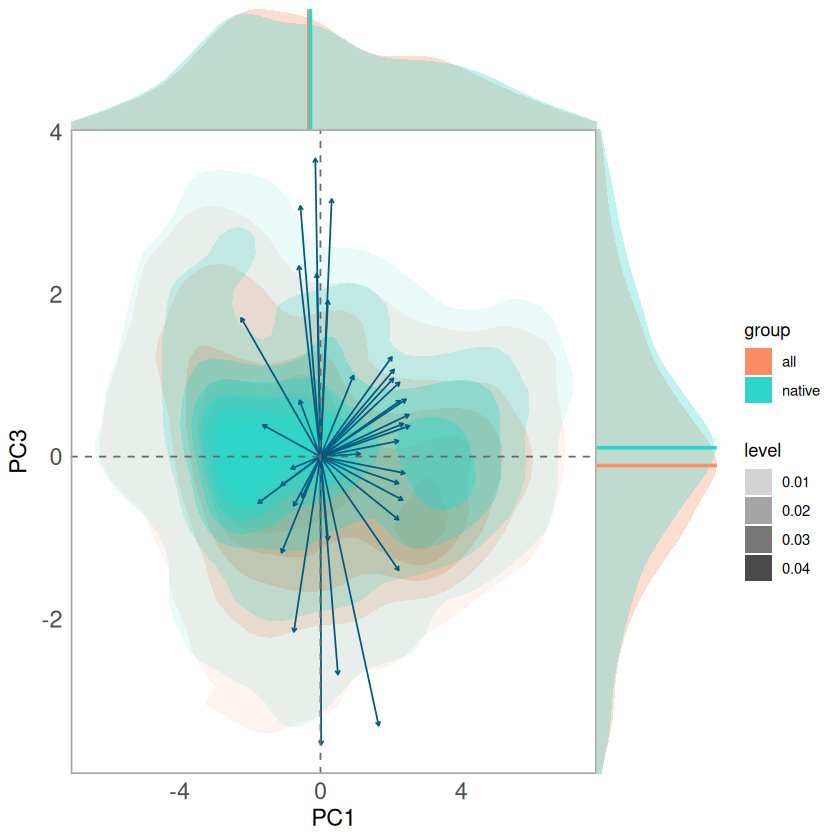

In [ ]:
### Biplot with Loadings (PC1 and PC3)

# Load required libraries
library(ggplot2)
library(cowplot)
library(grid)
library(dplyr)

# Step 1: Perform PCA (already done)
# pca_result <- prcomp(gbif_imputed %>% dplyr::select(starts_with("X")), center = TRUE, scale. = TRUE)

# Step 2: Extract PCA scores
pca_scores <- as.data.frame(pca_result$x[, c(1, 3)])  # PC1 and PC3
pca_scores$group <- gbif_imputed$group  # Adjust if your group column is named differently

# Step 3: Extract loadings and scale them
loadings <- as.data.frame(pca_result$rotation[, c(1, 3)])  # PC1 and PC3
loadings$trait <- rownames(loadings)

arrow_scale <- 10  # Scale for arrow length (tweak if needed)
loadings <- loadings %>%
    mutate(PC1 = PC1 * arrow_scale,
                 PC3 = PC3 * arrow_scale)

#flip PC3 gbif_glonaf_wcvp_all
pca_scores$PC3 <- -pca_scores$PC3
loadings$PC3 <- -loadings$PC3

# Define absolute offset distance
label_offset <- 0.3  # adjust this value to control how far the label is from the arrow tip

# Compute arrow unit vectors
loadings <- loadings %>%
    mutate(
        arrow_length = sqrt(PC1^2 + PC3^2),
        unit_x = PC1 / arrow_length,
        unit_y = PC3 / arrow_length,
        label_x = PC1 + label_offset * unit_x,
        label_y = PC3 + label_offset * unit_y
    )

loadings$trait <- stringr::str_extract(loadings$trait, "\\d+")

# Create base plot without default group aesthetic
p <- ggplot(pca_scores, aes(x = PC1, y = PC3)) +
    stat_density_2d(data = pca_scores,
                                    geom = "polygon", 
                                    aes(alpha = ..level.., fill = group, group = group), 
                                    bins = 10) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    theme_minimal() +
        theme(panel.grid = element_blank(), legend.position = "right",
            axis.title = element_text(size = 14),  # Increase font size for axis labels
            axis.text = element_text(size = 14),  # Increase font size for axis numbers
            panel.border = element_rect(color = "darkgrey", fill = NA, linewidth = 1)) +  # Add box around plot
        theme(panel.grid = element_blank(), legend.position = "right") +
    geom_segment(data = loadings,
                             aes(x = 0, y = 0, xend = PC1, yend = PC3),
                             arrow = arrow(length = unit(0.1, "cm")),
                             color = "#045A7FFF", size = 0.5) 

# Add grey line at 0,0
p <- p +
        geom_hline(yintercept = 0, color = "dimgrey", linetype = "dashed") +
        geom_vline(xintercept = 0, color = "dimgrey", linetype = "dashed")
        
# Step 5: Add marginal densities with median lines
xdens <- axis_canvas(p, axis = "x") + 
        geom_density(data = pca_scores, aes(x = PC1, fill = group), 
                                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
        scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
        geom_vline(data = pca_scores %>% group_by(group) %>% summarise(median_PC1 = median(PC1, na.rm = TRUE)),
                             aes(xintercept = median_PC1, color = group),
                             linetype = "solid", size = 1) +
        scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9"))

ydens <- axis_canvas(p, axis = "y", coord_flip = TRUE) + 
        geom_density(data = pca_scores, aes(x = PC3, fill = group), 
                                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
        scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
        geom_vline(data = pca_scores %>% group_by(group) %>% summarise(median_PC3 = median(PC3, na.rm = TRUE)),
                             aes(xintercept = median_PC3, color = group),
                             linetype = "solid", size = 1) +
        scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
        coord_flip()

# Step 6: Combine plot with marginal densities
final_plot <- p %>%
    insert_xaxis_grob(xdens, grid::unit(1, "in"), position = "top") %>%
    insert_yaxis_grob(ydens, grid::unit(1, "in"), position = "right") %>%
    ggdraw()

# Step 7: Save to PDF and print
png(file = "~/Func_Neo_Phytes/Results/Figures/pca_global_densities_biplot_GBIF_wcvp_all_CS_PC1_PC3_nolabels_log10.png", width = 9, height = 7, units = "in", res = 300)

print(final_plot)
dev.off()

# Also print to screen if running interactively
print(final_plot)


Warning message:
“Removed 2050 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 603 rows containing non-finite outside the scale range
(`stat_density()`).”


pdf 
  2

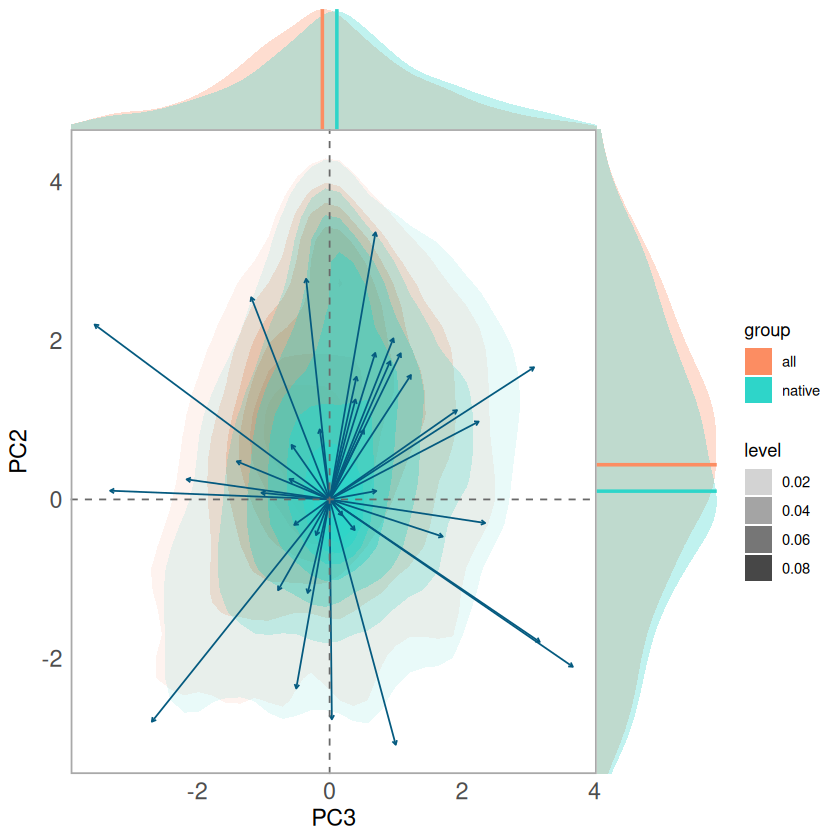

In [ ]:
### Biplot with Loadings (PC3 and PC2)

# Step 2: Extract PCA scores
pca_scores <- as.data.frame(pca_result$x[, c(3, 2)])  # PC3 and PC2
pca_scores$group <- gbif_imputed$group  # Adjust if your group column is named differently

# Step 3: Extract loadings and scale them
loadings <- as.data.frame(pca_result$rotation[, c(3, 2)])  # PC3 and PC2
loadings$trait <- rownames(loadings)

arrow_scale <- 10  # Scale for arrow length (tweak if needed)
loadings <- loadings %>%
    mutate(PC3 = PC3 * arrow_scale,
           PC2 = PC2 * arrow_scale)

# Flip PC2
pca_scores$PC3 <- -pca_scores$PC3
loadings$PC3 <- -loadings$PC3

# Define absolute offset distance
label_offset <- 0.3  # adjust this value to control how far the label is from the arrow tip

# Compute arrow unit vectors
loadings <- loadings %>%
    mutate(
        arrow_length = sqrt(PC3^2 + PC2^2),
        unit_x = PC3 / arrow_length,
        unit_y = PC2 / arrow_length,
        label_x = PC3 + label_offset * unit_x,
        label_y = PC2 + label_offset * unit_y
    )

loadings$trait <- stringr::str_extract(loadings$trait, "\\d+")

# Create base plot without default group aesthetic
p <- ggplot(pca_scores, aes(x = PC3, y = PC2)) +
    stat_density_2d(data = pca_scores,
                    geom = "polygon", 
                    aes(alpha = ..level.., fill = group, group = group), 
                    bins = 10) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    theme_minimal() +
        theme(panel.grid = element_blank(), legend.position = "right",
            axis.title = element_text(size = 14),  # Increase font size for axis labels
            axis.text = element_text(size = 14),  # Increase font size for axis numbers
            panel.border = element_rect(color = "darkgrey", fill = NA, linewidth = 1)) +  # Add box around plot
        theme(panel.grid = element_blank(), legend.position = "right") +
    geom_segment(data = loadings,
                 aes(x = 0, y = 0, xend = PC3, yend = PC2),
                 arrow = arrow(length = unit(0.1, "cm")),
                 color = "#045A7FFF", size = 0.5) 

# Add grey line at 0,0
p <- p +
        geom_hline(yintercept = 0, color = "dimgrey", linetype = "dashed") +
        geom_vline(xintercept = 0, color = "dimgrey", linetype = "dashed")
        
# Step 5: Add marginal densities with median lines
xdens <- axis_canvas(p, axis = "x") + 
        geom_density(data = pca_scores, aes(x = PC3, fill = group), 
                     alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
        scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
        geom_vline(data = pca_scores %>% group_by(group) %>% summarise(median_PC3 = median(PC3, na.rm = TRUE)),
                   aes(xintercept = median_PC3, color = group),
                   linetype = "solid", size = 1) +
        scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9"))

ydens <- axis_canvas(p, axis = "y", coord_flip = TRUE) + 
        geom_density(data = pca_scores, aes(x = PC2, fill = group), 
                     alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
        scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
        geom_vline(data = pca_scores %>% group_by(group) %>% summarise(median_PC2 = median(PC2, na.rm = TRUE)),
                   aes(xintercept = median_PC2, color = group),
                   linetype = "solid", size = 1) +
        scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
        coord_flip()

# Step 6: Combine plot with marginal densities
final_plot <- p %>%
    insert_xaxis_grob(xdens, grid::unit(1, "in"), position = "top") %>%
    insert_yaxis_grob(ydens, grid::unit(1, "in"), position = "right") %>%
    ggdraw()

# Step 7: Save to PNG and print
png(file = "~/Func_Neo_Phytes/Results/Figures/pca_global_densities_biplot_GBIF_wcvp_all_CS_PC3_PC2_nolabels_log10.png", width = 9, height = 7, units = "in", res = 300)

print(final_plot)
dev.off()

# Also print to screen if running interactively
print(final_plot)


Warning message:
“Removed 492 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 647 rows containing non-finite outside the scale range
(`stat_density()`).”


pdf 
  2

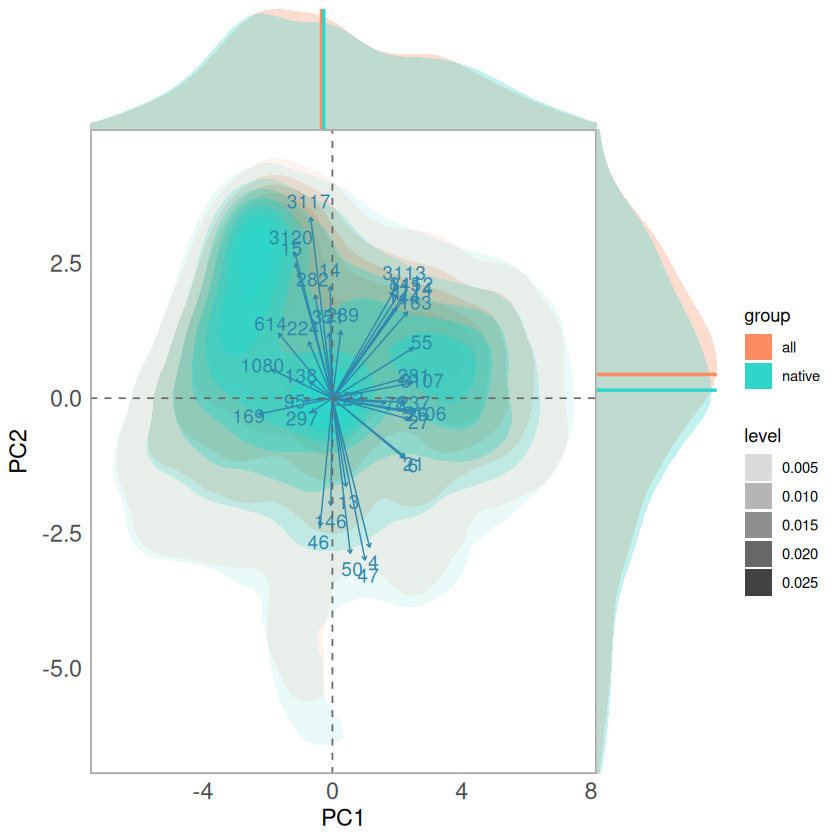

In [62]:
### Biplot with Loadings

# Load required libraries
library(ggplot2)
library(cowplot)
library(grid)
library(dplyr)

# Step 1: Perform PCA (already done)
# pca_result <- prcomp(gbif_imputed %>% dplyr::select(starts_with("X")), center = TRUE, scale. = TRUE)

# Step 2: Extract PCA scores
pca_scores <- as.data.frame(pca_result$x[, c(1, 2)])  # PC1 and PC2
pca_scores$group <- gbif_imputed$group  # Adjust if your group column is named differently

# Step 3: Extract loadings and scale them
loadings <- as.data.frame(pca_result$rotation[, c(1, 2)])  # PC1 and PC2
loadings$trait <- rownames(loadings)

arrow_scale <- 10  # Scale for arrow length (tweak if needed)
loadings <- loadings %>%
    mutate(PC1 = PC1 * arrow_scale,
           PC2 = PC2 * arrow_scale)

# Flip axes if needed (adjust based on your data)
# pca_scores$PC1 <- -pca_scores$PC1
# loadings$PC1 <- -loadings$PC1
# pca_scores$PC2 <- -pca_scores$PC2
# loadings$PC2 <- -loadings$PC2

# Define absolute offset distance
label_offset <- 0.3  # adjust this value to control how far the label is from the arrow tip

# Compute arrow unit vectors
loadings <- loadings %>%
    mutate(
        arrow_length = sqrt(PC1^2 + PC2^2),
        unit_x = PC1 / arrow_length,
        unit_y = PC2 / arrow_length,
        label_x = PC1 + label_offset * unit_x,
        label_y = PC2 + label_offset * unit_y
    )

loadings$trait <- stringr::str_extract(loadings$trait, "\\d+")

# Create base plot without default group aesthetic
p <- ggplot(pca_scores, aes(x = PC1, y = PC2)) +
    stat_density_2d(data = pca_scores,
                    geom = "polygon", 
                    aes(alpha = ..level.., fill = group, group = group), 
                    bins = 10) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    theme_minimal() +
    theme(panel.grid = element_blank(), legend.position = "right",
          axis.title = element_text(size = 14),  # Increase font size for axis labels
          axis.text = element_text(size = 14),  # Increase font size for axis numbers
          panel.border = element_rect(color = "darkgrey", fill = NA, linewidth = 1)) +  # Add box around plot
    geom_segment(data = loadings,
                 aes(x = 0, y = 0, xend = PC1, yend = PC2),
                 arrow = arrow(length = unit(0.1, "cm")),
                 color = "#2F86AC", size = 0.4) +
    geom_text(data = loadings,
              aes(x = label_x, y = label_y, label = trait),
              color = "#2F86AC", size = 4, hjust = 0.5, vjust = 0.5)

# Add grey line at 0,0
p <- p +
    geom_hline(yintercept = 0, color = "dimgrey", linetype = "dashed") +
    geom_vline(xintercept = 0, color = "dimgrey", linetype = "dashed")

# Step 5: Add marginal densities with median lines
xdens <- axis_canvas(p, axis = "x") + 
    geom_density(data = pca_scores, aes(x = PC1, fill = group), 
                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    geom_vline(data = pca_scores %>% group_by(group) %>% summarise(median_PC1 = median(PC1, na.rm = TRUE)),
               aes(xintercept = median_PC1, color = group),
               linetype = "solid", size = 1) +
    scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9"))

ydens <- axis_canvas(p, axis = "y", coord_flip = TRUE) + 
    geom_density(data = pca_scores, aes(x = PC2, fill = group), 
                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    geom_vline(data = pca_scores %>% group_by(group) %>% summarise(median_PC2 = median(PC2, na.rm = TRUE)),
               aes(xintercept = median_PC2, color = group),
               linetype = "solid", size = 1) +
    scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    coord_flip()

# Step 6: Combine plot with marginal densities
final_plot <- p %>%
    insert_xaxis_grob(xdens, grid::unit(1, "in"), position = "top") %>%
    insert_yaxis_grob(ydens, grid::unit(1, "in"), position = "right") %>%
    ggdraw()

# Step 7: Save to PDF and print
png(file = "~/Func_Neo_Phytes/Results/Figures/pca_global_densities_biplot_GBIF_wcvp_all_CS_PC1_2_log10_angio.png", width = 9, height = 7, units = "in", res = 300)

print(final_plot)
dev.off()

# Also print to screen if running interactively
print(final_plot)


Warning message:
“Removed 1886 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 475 rows containing non-finite outside the scale range
(`stat_density()`).”


pdf 
  2

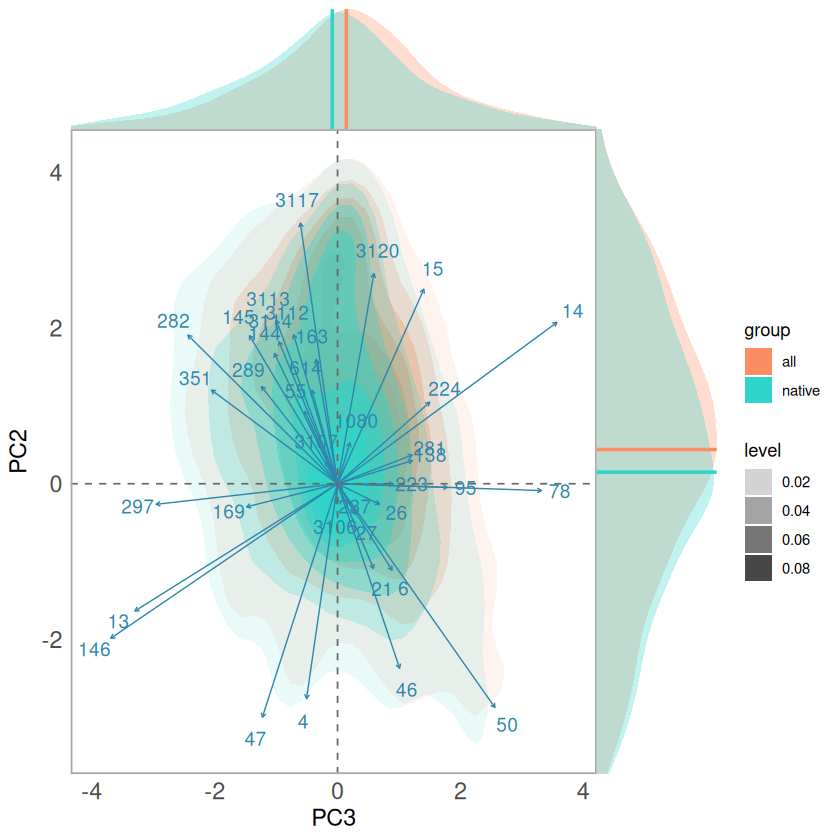

In [63]:
### Biplot with Loadings


# Load required libraries
library(ggplot2)
library(cowplot)
library(grid)
library(dplyr)

# Step 1: Perform PCA (already done)
# pca_result <- prcomp(gbif_imputed %>% dplyr::select(starts_with("X")), center = TRUE, scale. = TRUE)

# Step 2: Extract PCA scores
pca_scores <- as.data.frame(pca_result$x[, c(3, 2)])  # PC3 and PC2
pca_scores$group <- gbif_imputed$group  # Adjust if your group column is named differently

# Step 3: Extract loadings and scale them
loadings <- as.data.frame(pca_result$rotation[, c(3, 2)])  # PC3 and PC2
loadings$trait <- rownames(loadings)

arrow_scale <- 10  # Scale for arrow length (tweak if needed)
loadings <- loadings %>%
    mutate(PC3 = PC3 * arrow_scale,
           PC2 = PC2 * arrow_scale)


#flip PC3 gbif_glonaf_wcvp_all
pca_scores$PC3 <- -pca_scores$PC3
loadings$PC3 <- -loadings$PC3

# Define absolute offset distance
label_offset <- 0.3  # adjust this value to control how far the label is from the arrow tip

# Compute arrow unit vectors
loadings <- loadings %>%
    mutate(
        arrow_length = sqrt(PC3^2 + PC2^2),
        unit_x = PC3 / arrow_length,
        unit_y = PC2 / arrow_length,
        label_x = PC3 + label_offset * unit_x,
        label_y = PC2 + label_offset * unit_y
    )

loadings$trait <- stringr::str_extract(loadings$trait, "\\d+")

# Create base plot without default group aesthetic
p <- ggplot(pca_scores, aes(x = PC3, y = PC2)) +
    stat_density_2d(data = pca_scores,
                    geom = "polygon", 
                    aes(alpha = ..level.., fill = group, group = group), 
                    bins = 10) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    theme_minimal() +
    theme(panel.grid = element_blank(), legend.position = "right",
          axis.title = element_text(size = 14),  # Increase font size for axis labels
          axis.text = element_text(size = 14),  # Increase font size for axis numbers
          panel.border = element_rect(color = "darkgrey", fill = NA, linewidth = 1)) +  # Add box around plot
    geom_segment(data = loadings,
                 aes(x = 0, y = 0, xend = PC3, yend = PC2),
                 arrow = arrow(length = unit(0.1, "cm")),
                 color = "#2F86AC", size = 0.4) +
    geom_text(data = loadings,
              aes(x = label_x, y = label_y, label = trait),
              color = "#2F86AC", size = 4, hjust = 0.5, vjust = 0.5)

# Add grey line at 0,0
p <- p +
    geom_hline(yintercept = 0, color = "dimgrey", linetype = "dashed") +
    geom_vline(xintercept = 0, color = "dimgrey", linetype = "dashed")

# Step 5: Add marginal densities with median lines
xdens <- axis_canvas(p, axis = "x") + 
    geom_density(data = pca_scores, aes(x = PC3, fill = group), 
                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    geom_vline(data = pca_scores %>% group_by(group) %>% summarise(median_PC3 = median(PC3, na.rm = TRUE)),
               aes(xintercept = median_PC3, color = group),
               linetype = "solid", size = 1) +
    scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9"))

ydens <- axis_canvas(p, axis = "y", coord_flip = TRUE) + 
    geom_density(data = pca_scores, aes(x = PC2, fill = group), 
                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    geom_vline(data = pca_scores %>% group_by(group) %>% summarise(median_PC2 = median(PC2, na.rm = TRUE)),
               aes(xintercept = median_PC2, color = group),
               linetype = "solid", size = 1) +
    scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    coord_flip()

# Step 6: Combine plot with marginal densities
final_plot <- p %>%
    insert_xaxis_grob(xdens, grid::unit(1, "in"), position = "top") %>%
    insert_yaxis_grob(ydens, grid::unit(1, "in"), position = "right") %>%
    ggdraw()

# Step 7: Save to PDF and print
png(file = "~/Func_Neo_Phytes/Results/Figures/pca_global_densities_biplot_GBIF_wcvp_all_CS_PC3_2_log10_angio.png", width = 8, height = 7, units = "in", res = 300)

print(final_plot)
dev.off()

# Also print to screen if running interactively
print(final_plot)


Warning message:
“Removed 462 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 816 rows containing non-finite outside the scale range
(`stat_density()`).”


pdf 
  2

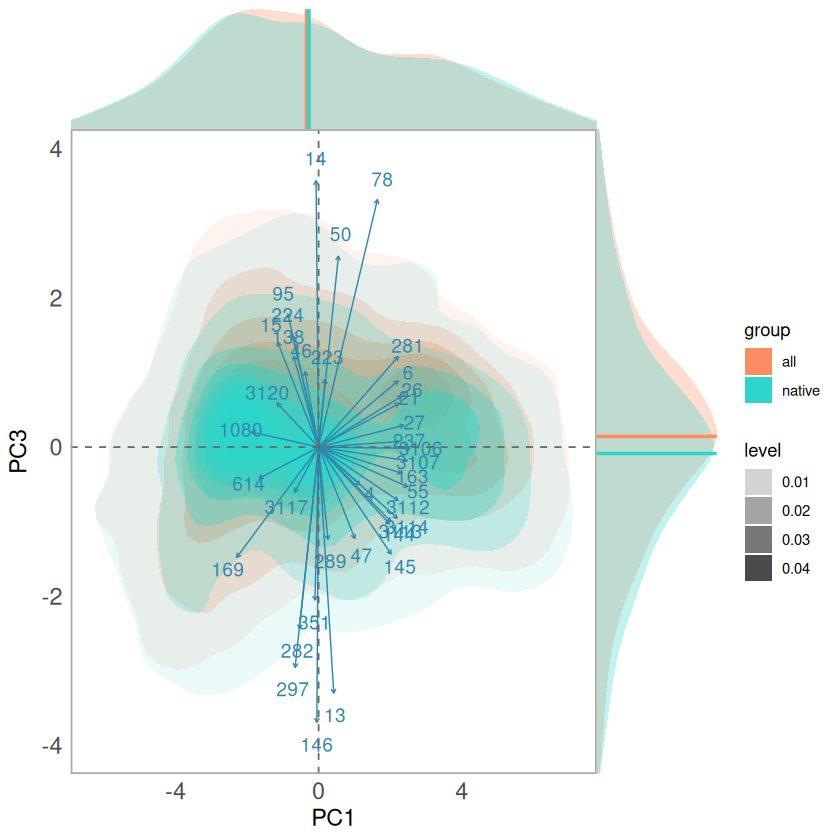

In [64]:
### Biplot with Loadings


# Load required libraries
library(ggplot2)
library(cowplot)
library(grid)
library(dplyr)

# Step 1: Perform PCA (already done)
# pca_result <- prcomp(gbif_imputed %>% dplyr::select(starts_with("X")), center = TRUE, scale. = TRUE)

# Step 2: Extract PCA scores
pca_scores <- as.data.frame(pca_result$x[, c(1, 3)])  # PC1 and PC3
pca_scores$group <- gbif_imputed$group  # Adjust if your group column is named differently

# Step 3: Extract loadings and scale them
loadings <- as.data.frame(pca_result$rotation[, c(1, 3)])  # PC1 and PC3
loadings$trait <- rownames(loadings)

arrow_scale <- 10  # Scale for arrow length (tweak if needed)
loadings <- loadings %>%
    mutate(PC1 = PC1 * arrow_scale,
           PC3 = PC3 * arrow_scale)


# Flip PC3
pca_scores$PC3 <- -pca_scores$PC3
loadings$PC3 <- -loadings$PC3

# Define absolute offset distance
label_offset <- 0.3  # adjust this value to control how far the label is from the arrow tip

# Compute arrow unit vectors
loadings <- loadings %>%
    mutate(
        arrow_length = sqrt(PC1^2 + PC3^2),
        unit_x = PC1 / arrow_length,
        unit_y = PC3 / arrow_length,
        label_x = PC1 + label_offset * unit_x,
        label_y = PC3 + label_offset * unit_y
    )

loadings$trait <- stringr::str_extract(loadings$trait, "\\d+")

# Create base plot without default group aesthetic
p <- ggplot(pca_scores, aes(x = PC1, y = PC3)) +
    stat_density_2d(data = pca_scores,
                    geom = "polygon", 
                    aes(alpha = ..level.., fill = group, group = group), 
                    bins = 10) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    theme_minimal() +
    theme(panel.grid = element_blank(), legend.position = "right",
          axis.title = element_text(size = 14),  # Increase font size for axis labels
          axis.text = element_text(size = 14),  # Increase font size for axis numbers
          panel.border = element_rect(color = "darkgrey", fill = NA, linewidth = 1)) +  # Add box around plot
    geom_segment(data = loadings,
                 aes(x = 0, y = 0, xend = PC1, yend = PC3),
                 arrow = arrow(length = unit(0.1, "cm")),
                 color = "#2F86AC", size = 0.4) +
    geom_text(data = loadings,
              aes(x = label_x, y = label_y, label = trait),
              color = "#2F86AC", size = 4, hjust = 0.5, vjust = 0.5)

# Add grey line at 0,0
p <- p +
    geom_hline(yintercept = 0, color = "dimgrey", linetype = "dashed") +
    geom_vline(xintercept = 0, color = "dimgrey", linetype = "dashed")

# Step 5: Add marginal densities with median lines
xdens <- axis_canvas(p, axis = "x") + 
    geom_density(data = pca_scores, aes(x = PC1, fill = group), 
                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    geom_vline(data = pca_scores %>% group_by(group) %>% summarise(median_PC1 = median(PC1, na.rm = TRUE)),
               aes(xintercept = median_PC1, color = group),
               linetype = "solid", size = 1) +
    scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9"))

ydens <- axis_canvas(p, axis = "y", coord_flip = TRUE) + 
    geom_density(data = pca_scores, aes(x = PC3, fill = group), 
                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    geom_vline(data = pca_scores %>% group_by(group) %>% summarise(median_PC3 = median(PC3, na.rm = TRUE)),
               aes(xintercept = median_PC3, color = group),
               linetype = "solid", size = 1) +
    scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    coord_flip()

# Step 6: Combine plot with marginal densities
final_plot <- p %>%
    insert_xaxis_grob(xdens, grid::unit(1, "in"), position = "top") %>%
    insert_yaxis_grob(ydens, grid::unit(1, "in"), position = "right") %>%
    ggdraw()

# Step 7: Save to PNG and print
png(file = "~/Func_Neo_Phytes/Results/Figures/pca_global_densities_biplot_GBIF_wcvp_all_CS_PC1_3_log10_angio.png", width = 8, height = 7, units = "in", res = 300)

print(final_plot)
dev.off()

# Also print to screen if running interactively
print(final_plot)


In [ ]:
# plot vecor for each point in PCA space from native to all
pca_vector_plot <- ggplot(pca_scores_wide, aes(x = PC1_native  


Warning message:
“Removed 140 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 816 rows containing non-finite outside the scale range
(`stat_density()`).”


pdf 
  2

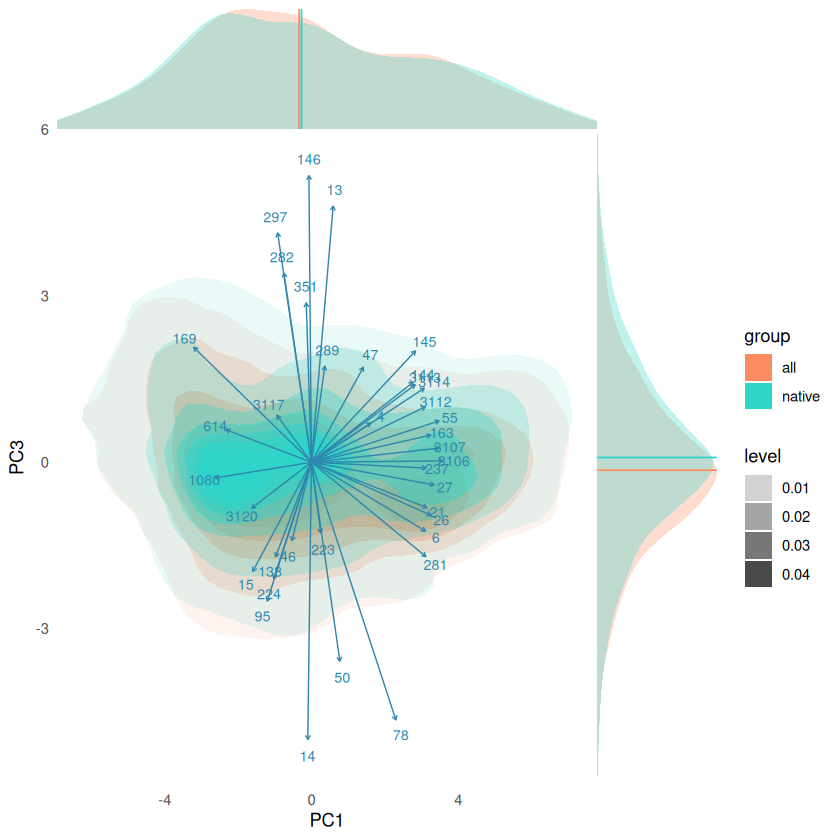

In [65]:
### Biplot with Loadings (PC1 vs PC3)

# Step 2: Extract PCA scores
pca_scores <- as.data.frame(pca_result$x[, c(1, 3)])  # PC1 and PC3
colnames(pca_scores) <- c("PC1", "PC3")  # Rename columns for clarity
pca_scores$group <- gbif_imputed$group  # Adjust if your group column is named differently

# Step 3: Extract loadings and scale them
loadings <- as.data.frame(pca_result$rotation[, c(1, 3)])  # PC1 and PC3
colnames(loadings) <- c("PC1", "PC3")  # Rename columns for clarity
loadings$trait <- rownames(loadings)

arrow_scale <- 14  # Scale for arrow length (tweak if needed)
loadings <- loadings %>%
    mutate(PC1 = PC1 * arrow_scale,
           PC3 = PC3 * arrow_scale)

# Define absolute offset distance
label_offset <- 0.3  # adjust this value to control how far the label is from the arrow tip

# Compute arrow unit vectors
loadings <- loadings %>%
    mutate(
        arrow_length = sqrt(PC1^2 + PC3^2),
        unit_x = PC1 / arrow_length,
        unit_y = PC3 / arrow_length,
        label_x = PC1 + label_offset * unit_x,
        label_y = PC3 + label_offset * unit_y
    )

loadings$trait <- stringr::str_extract(loadings$trait, "\\d+")

# Create base plot without default group aesthetic
p <- ggplot(pca_scores, aes(x = PC1, y = PC3)) +
    stat_density_2d(data = pca_scores,
                    geom = "polygon", 
                    aes(alpha = ..level.., fill = group, group = group), 
                    bins = 10) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    theme_minimal() +
    theme(panel.grid = element_blank(), legend.position = "right") +
    geom_segment(data = loadings,
                 aes(x = 0, y = 0, xend = PC1, yend = PC3),
                 arrow = arrow(length = unit(0.1, "cm")),
                 color = "#2F86AC", size = 0.4) +
    geom_text(data = loadings,
              aes(x = label_x, y = label_y, label = trait),
              color = "#2F86AC", size = 3, hjust = 0.5, vjust = 0.5)

# Step 5: Add marginal densities with median lines
xdens <- axis_canvas(p, axis = "x") + 
        geom_density(data = pca_scores, aes(x = PC1, fill = group), 
                     alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
        scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
        geom_vline(data = pca_scores %>% group_by(group) %>% summarise(median_PC1 = median(PC1, na.rm = TRUE)),
                   aes(xintercept = median_PC1, color = group),
                   linetype = "solid", size = 0.5) +
        scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9"))

ydens <- axis_canvas(p, axis = "y", coord_flip = TRUE) + 
        geom_density(data = pca_scores, aes(x = PC3, fill = group), 
                     alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
        scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
        geom_vline(data = pca_scores %>% group_by(group) %>% summarise(median_PC3 = median(PC3, na.rm = TRUE)),
                   aes(xintercept = median_PC3, color = group),
                   linetype = "solid", size = 0.5) +
        scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
        coord_flip()

# Step 6: Combine plot with marginal densities
final_plot <- p %>%
    insert_xaxis_grob(xdens, grid::unit(1, "in"), position = "top") %>%
    insert_yaxis_grob(ydens, grid::unit(1, "in"), position = "right") %>%
    ggdraw()

# Step 7: Save to PNG and print
#png(file = "~/Func_Neo_Phytes/Results/Figures/pca_global_densities_biplot_GBIF_wcvp_all_CS_PC1_PC3.png", width = 12, height = 7, units = "in", res = 300)
png(file = "~/Func_Neo_Phytes/Results/Figures/pca_global_densities_biplot_GBIF_wcvp_all_CS_PC1_PC3_log10_angio.png", width = 12, height = 7, units = "in", res = 300)

print(final_plot)
dev.off()

# Also print to screen if running interactively
print(final_plot)


Warning message:
“Removed 155 rows containing non-finite outside the scale range
(`stat_density()`).”
Warning message:
“Removed 605 rows containing non-finite outside the scale range
(`stat_density()`).”


pdf 
  2

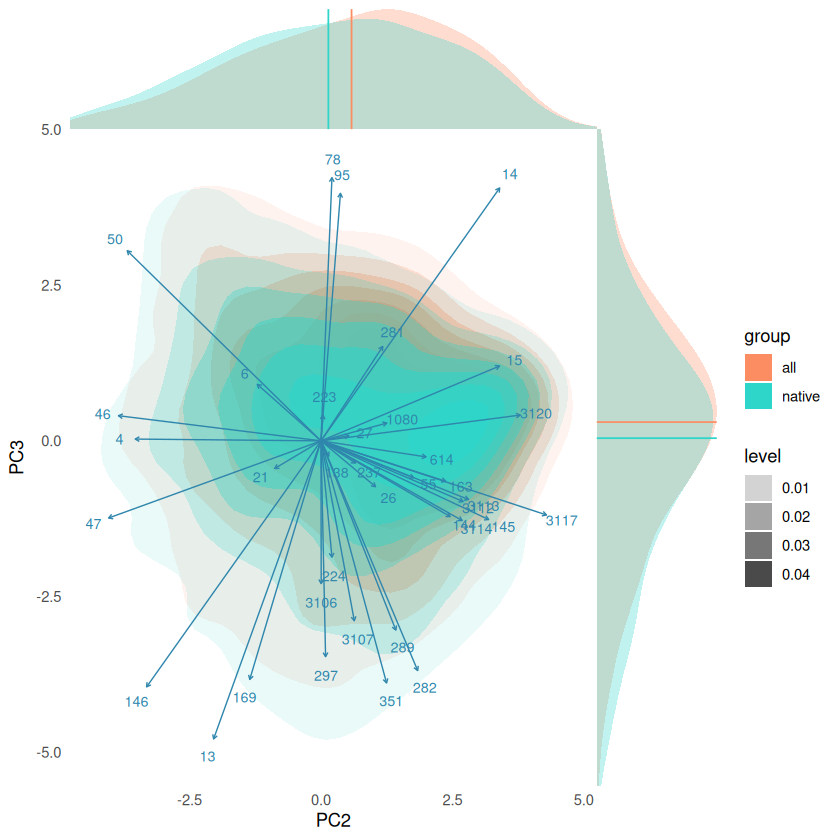

In [ ]:
### Biplot with Loadings (PC2 vs PC3)

# Step 2: Extract PCA scores
pca_scores <- as.data.frame(pca_result$x[, 2:3])  # PC2 and PC3
colnames(pca_scores) <- c("PC2", "PC3")  # Rename columns for clarity
pca_scores$group <- gbif_imputed$group  # Adjust if your group column is named differently

# Step 3: Extract loadings and scale them
loadings <- as.data.frame(pca_result$rotation[, 2:3])  # PC2 and PC3
colnames(loadings) <- c("PC2", "PC3")  # Rename columns for clarity
loadings$trait <- rownames(loadings)

arrow_scale <- 14  # Scale for arrow length (tweak if needed)
loadings <- loadings %>%
    mutate(PC2 = PC2 * arrow_scale,
                 PC3 = PC3 * arrow_scale)

# Define absolute offset distance
label_offset <- 0.3  # adjust this value to control how far the label is from the arrow tip

# Compute arrow unit vectors
loadings <- loadings %>%
    mutate(
        arrow_length = sqrt(PC2^2 + PC3^2),
        unit_x = PC2 / arrow_length,
        unit_y = PC3 / arrow_length,
        label_x = PC2 + label_offset * unit_x,
        label_y = PC3 + label_offset * unit_y
    )

loadings$trait <- stringr::str_extract(loadings$trait, "\\d+")

# Create base plot without default group aesthetic
p <- ggplot(pca_scores, aes(x = PC2, y = PC3)) +
    stat_density_2d(data = pca_scores,
                                    geom = "polygon", 
                                    aes(alpha = ..level.., fill = group, group = group), 
                                    bins = 10) +
    scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
    theme_minimal() +
    theme(panel.grid = element_blank(), legend.position = "right") +
    geom_segment(data = loadings,
                             aes(x = 0, y = 0, xend = PC2, yend = PC3),
                             arrow = arrow(length = unit(0.1, "cm")),
                             color = "#2F86AC", size = 0.4) +
    geom_text(data = loadings,
                    aes(x = label_x, y = label_y, label = trait),
                    color = "#2F86AC", size = 3, hjust = 0.5, vjust = 0.5)

# Step 5: Add marginal densities with median lines
xdens <- axis_canvas(p, axis = "x") + 
        geom_density(data = pca_scores, aes(x = PC2, fill = group), 
                                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
        scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
        geom_vline(data = pca_scores %>% group_by(group) %>% summarise(median_PC2 = median(PC2, na.rm = TRUE)),
                             aes(xintercept = median_PC2, color = group),
                             linetype = "solid", size = 0.5) +
        scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9"))

ydens <- axis_canvas(p, axis = "y", coord_flip = TRUE) + 
        geom_density(data = pca_scores, aes(x = PC3, fill = group), 
                                 alpha = 0.3, size = 0.5, adjust = 1.5, color = NA) +
        scale_fill_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
        geom_vline(data = pca_scores %>% group_by(group) %>% summarise(median_PC3 = median(PC3, na.rm = TRUE)),
                             aes(xintercept = median_PC3, color = group),
                             linetype = "solid", size = 0.5) +
        scale_color_manual(values = c("all" = "#fc8d62", "native" = "#2ed5c9")) +
        coord_flip()

# Step 6: Combine plot with marginal densities
final_plot <- p %>%
    insert_xaxis_grob(xdens, grid::unit(1, "in"), position = "top") %>%
    insert_yaxis_grob(ydens, grid::unit(1, "in"), position = "right") %>%
    ggdraw()

# Step 7: Save to PNG and print
#png(file = "~/Func_Neo_Phytes/Results/Figures/pca_global_densities_biplot_GBIF_wcvp_all_CS_PC2_PC3.png", width = 12, height = 7, units = "in", res = 300)
png(file = "~/Func_Neo_Phytes/Results/Figures/pca_global_densities_biplot_GBIF_wcvp_all_CS_PC2_PC3_n100.png", width = 12, height = 7, units = "in", res = 300)

print(final_plot)
dev.off()

# Also print to screen if running interactively
print(final_plot)
